# PhishGuard — Machine Learning-Based Phishing URL Detection

**ChatGPT-built recovery and improvement edition**  
A reproducible, domain-aware machine-learning workflow with an audited 16-feature URL extractor and a Colab-friendly interactive interface.

## Project decisions and honest limitations

- Target labels: `0 = Phishing`, `1 = Legitimate`.
- The source dataset contains 101,219 rows, 16 numeric URL features, one URL column and one target column. Cleaning removes missing target labels and exact duplicate rows.
- The original Logistic Regression baseline (`L2`, `C=1.0`, `lbfgs`, `max_iter=1000`, seed 42) is retained as a candidate. A controlled benign-path augmentation experiment is added because the source data contains almost no legitimate URLs with paths or queries.
- Training, validation and test partitions are grouped by registrable domain to reduce domain leakage. Scaling is fitted only on the training partition.
- The notebook audits whether the original 16 feature formulas can be reproduced from raw URLs. Any mismatch is reported rather than concealed. The augmentation experiment uses only legitimate domains from the training partition; held-out validation domains provide a separate synthetic path stress test.
- The final UI uses the same extractor, scaler and fitted Logistic Regression selected in this notebook. It never opens or contacts submitted URLs.
- URL-only lexical models cannot reliably distinguish a legitimate long URL from a phishing URL when their observable features overlap. A score is not a guarantee or a calibrated real-world probability.

**Run all cells from top to bottom in Google Colab.** Upload `url_features_extracted1.csv` when prompted if it is not already in the runtime.

> **Model limitation:** The source dataset contains fewer legitimate rows than phishing rows and has very different host/domain repetition patterns by class. This notebook measures hostname/domain diversity and audits inference-feature parity. It does not invent extra legitimate URLs, use allowlists, or claim that demonstration URLs are an independent benchmark.

> **How to run:** Upload `url_features_extracted1.csv` when prompted in Google Colab, then run all cells from top to bottom. Phase 8 launches an offline UI; submitted URLs are parsed locally and never opened.


In [1]:
# Runtime setup and deterministic configuration
import os, re, math, json, ipaddress, warnings, html, sys, subprocess, importlib.util
from collections import Counter
from urllib.parse import urlparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

RANDOM_STATE = 42
TARGET_COL = "ClassLabel"
URL_COL = "URL"
LABEL_MAP = {0: "Phishing", 1: "Legitimate"}
FEATURES = [
    "url_length", "has_ip_address", "dot_count", "https_flag",
    "url_entropy", "token_count", "subdomain_count", "query_param_count",
    "tld_length", "path_length", "has_hyphen_in_domain", "number_of_digits",
    "tld_popularity", "suspicious_file_extension", "domain_name_length",
    "percentage_numeric_chars"
]
FINAL_THRESHOLD = 0.50
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__)
print("Seed:", RANDOM_STATE, "| Features:", len(FEATURES), "| Decision threshold:", FINAL_THRESHOLD)


Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6
Seed: 42 | Features: 16 | Decision threshold: 0.5


In [2]:
# Shared evaluation function: phishing (class 0) is the positive class.
def evaluate_phishing(y_true, score, threshold=0.50):
    y_true=np.asarray(y_true).astype(int)
    pred=np.where(np.asarray(score)>=threshold,0,1)
    y_pos=(y_true==0).astype(int)
    return {
        "Accuracy":accuracy_score(y_true,pred),
        "Balanced Accuracy":balanced_accuracy_score(y_true,pred),
        "Phishing Precision":precision_score(y_true,pred,pos_label=0,zero_division=0),
        "Phishing Recall":recall_score(y_true,pred,pos_label=0,zero_division=0),
        "Phishing F1":f1_score(y_true,pred,pos_label=0,zero_division=0),
        "ROC-AUC":roc_auc_score(y_pos,score),
        "PR-AUC":average_precision_score(y_pos,score),
        "Predictions":pred,
        "Confusion Matrix":confusion_matrix(y_true,pred,labels=[0,1]),
    }
print("Evaluation helper ready; class 0 is treated as the positive phishing class.")

Evaluation helper ready; class 0 is treated as the positive phishing class.


## PHASE 1 — DATASET COLLECTION AND VERIFICATION



### 1.1 — Phase 1 Introduction and Objectives



In [3]:
print("Phase 1 objective: verify the source file, schema, labels and data quality before modifying data.")

Phase 1 objective: verify the source file, schema, labels and data quality before modifying data.


### 1.2 — Import Required Libraries



In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report)
try:
    import tldextract
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tldextract"])
    import tldextract
try:
    from xgboost import XGBClassifier
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    from xgboost import XGBClassifier
print("Core modelling libraries imported.")

Core modelling libraries imported.


### 1.3 — Define Dataset Path and Configuration



In [5]:
DATASET_CANDIDATES = ["/content/url_features_extracted1.csv", "url_features_extracted1.csv", "/mnt/data/url_features_extracted1.csv"]
CSV_PATH = next((p for p in DATASET_CANDIDATES if os.path.exists(p)), None)
if CSV_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    except Exception:
        CSV_PATH = None
if CSV_PATH is None:
    raise FileNotFoundError("Upload the original url_features_extracted1.csv dataset.")
print("Dataset path:", CSV_PATH)

Saving url_features_extracted1.csv to url_features_extracted1.csv
Dataset path: url_features_extracted1.csv


### 1.4 — Load Original Dataset



In [6]:
df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df):,} rows × {df.shape[1]} columns")
display(df.head())

Loaded 101,219 rows × 18 columns


,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


### 1.5 — Display First Five Records



In [7]:
display(df.head(5))

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


### 1.6 — Display Last Five Records



In [8]:
display(df.tail(5))

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
101214,https://www.cruiseamerica.com,29,0,2,1,3.909368,5,1,1,3,0,0,0,1,0,13,0.0,1.0
101215,https://www.eosc-synergy.eu,27,0,2,1,3.930270,5,1,1,2,0,1,0,0,0,12,0.0,1.0
101216,https://www.activecyber.us,26,0,2,1,3.950064,5,1,1,2,0,0,0,0,0,11,0.0,1.0
101217,https://www.summerwine.net,26,0,2,1,3.642371,5,1,1,3,0,0,0,1,0,10,0.0,1.0
101218,https://www.lawyersgunsmoneyblog.com,36,0,2,1,4.183542,5,1,1,3,0,0,0,1,0,20,0.0,1.0


### 1.7 — Inspect Dataset Dimensions



In [9]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Rows: 101219 | Columns: 18


### 1.8 — Display Column Names



In [10]:
display(pd.DataFrame({"Column": df.columns, "Dtype": df.dtypes.astype(str).values}))

,Column,Dtype
0,URL,object
1,url_length,int64
2,has_ip_address,int64
3,dot_count,int64
4,https_flag,int64
5,url_entropy,float64
6,token_count,int64
7,subdomain_count,int64
8,query_param_count,int64
9,tld_length,int64


### 1.9 — Identify the 16 Input Features



In [11]:
missing_features = [f for f in FEATURES if f not in df.columns]
print("Expected input feature count:", len(FEATURES))
print("Missing expected features:", missing_features if missing_features else "None")
assert not missing_features, "The supplied CSV does not contain the complete 16-feature schema."

Expected input feature count: 16
Missing expected features: None


### 1.10 — Identify the Target Column



In [12]:
assert TARGET_COL in df.columns, f"Missing target column: {TARGET_COL}"
print("Target column:", TARGET_COL)
display(df[TARGET_COL].value_counts(dropna=False).rename_axis("ClassLabel").to_frame("Rows"))

Target column: ClassLabel


,Rows
ClassLabel,
0.0,63678
1.0,37540
NaN,1


### 1.11 — Inspect Data Types



In [13]:
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(), "null": df.isna().sum()}))

,dtype,non_null,null
URL,object,101219,0
url_length,int64,101219,0
has_ip_address,int64,101219,0
dot_count,int64,101219,0
https_flag,int64,101219,0
url_entropy,float64,101219,0
token_count,int64,101219,0
subdomain_count,int64,101219,0
query_param_count,int64,101219,0
tld_length,int64,101219,0


### 1.12 — Check Missing Values



In [14]:
missing_report = pd.DataFrame({"Missing": df.isna().sum(), "Missing_%": (df.isna().mean()*100).round(3)})
display(missing_report[missing_report.Missing.gt(0)])
print("Total missing cells:", int(df.isna().sum().sum()))

,Missing,Missing_%
ClassLabel,1,0.001


Total missing cells: 1


### 1.13 — Check Duplicate Records



In [15]:
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Repeated URL rows:", int(df.duplicated(subset=[URL_COL]).sum()))
conflicts = df.dropna(subset=[TARGET_COL]).groupby(URL_COL)[TARGET_COL].nunique().gt(1).sum()
print("URLs with conflicting labels:", int(conflicts))

Exact duplicate rows: 346
Repeated URL rows: 346
URLs with conflicting labels: 0


### 1.14 — Display Target Class Distribution



In [16]:
raw_counts = df[TARGET_COL].value_counts(dropna=False).sort_index()
display(raw_counts.rename(index=LABEL_MAP).to_frame("Count"))

,Count
ClassLabel,
Phishing,63678
Legitimate,37540
NaN,1


### 1.15 — Display Target Class Percentages



In [17]:
raw_pct = (df[TARGET_COL].value_counts(normalize=True, dropna=False).sort_index()*100).rename(index=LABEL_MAP)
display(raw_pct.round(2).to_frame("Percentage"))

,Percentage
ClassLabel,
Phishing,62.91
Legitimate,37.09
NaN,0.00


### 1.16 — Phase 1 Summary and Findings



In [18]:
print("PHASE 1 AUDIT")
print("Raw rows:", len(df), "| Missing targets:", int(df[TARGET_COL].isna().sum()), "| Exact duplicates:", int(df.duplicated().sum()))
print("Class 0 = Phishing; Class 1 = Legitimate. No rows have been changed yet.")

PHASE 1 AUDIT
Raw rows: 101219 | Missing targets: 1 | Exact duplicates: 346
Class 0 = Phishing; Class 1 = Legitimate. No rows have been changed yet.


## PHASE 2 — EXPLORATORY DATA ANALYSIS



### 2.1 — Phase 2 Introduction



In [19]:
print("Phase 2 objective: understand class balance, URL feature ranges and potential distribution gaps.")

Phase 2 objective: understand class balance, URL feature ranges and potential distribution gaps.


### 2.2 — Dataset Statistical Overview



In [20]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
URL,101219,100873,https://www.forbesindia.com/article/explainers...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url_length,101219.0,NaN,NaN,NaN,35.060996,16.805678,7.0,27.0,31.0,35.0,474.0
has_ip_address,101219.0,NaN,NaN,NaN,0.484879,0.499774,0.0,0.0,0.0,1.0,1.0
dot_count,101219.0,NaN,NaN,NaN,3.007775,0.946612,0.0,2.0,3.0,4.0,19.0
https_flag,101219.0,NaN,NaN,NaN,0.405645,0.491019,0.0,0.0,0.0,1.0,1.0
url_entropy,101219.0,NaN,NaN,NaN,3.976112,0.307068,2.521641,3.770942,3.937193,4.100817,5.871503
token_count,101219.0,NaN,NaN,NaN,6.885733,1.670271,1.0,5.0,7.0,8.0,48.0
subdomain_count,101219.0,NaN,NaN,NaN,1.511515,0.624755,-1.0,1.0,2.0,2.0,5.0
query_param_count,101219.0,NaN,NaN,NaN,1.010591,0.202794,1.0,1.0,1.0,1.0,14.0
tld_length,101219.0,NaN,NaN,NaN,5.00327,2.917429,0.0,3.0,3.0,8.0,10.0


### 2.3 — Feature Descriptive Statistics



In [21]:
display(df[FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
url_length,101219.0,35.060996,16.805678,7.000000,27.000000,31.000000,35.000000,474.000000
has_ip_address,101219.0,0.484879,0.499774,0.000000,0.000000,0.000000,1.000000,1.000000
dot_count,101219.0,3.007775,0.946612,0.000000,2.000000,3.000000,4.000000,19.000000
https_flag,101219.0,0.405645,0.491019,0.000000,0.000000,0.000000,1.000000,1.000000
url_entropy,101219.0,3.976112,0.307068,2.521641,3.770942,3.937193,4.100817,5.871503
token_count,101219.0,6.885733,1.670271,1.000000,5.000000,7.000000,8.000000,48.000000
subdomain_count,101219.0,1.511515,0.624755,-1.000000,1.000000,2.000000,2.000000,5.000000
query_param_count,101219.0,1.010591,0.202794,1.000000,1.000000,1.000000,1.000000,14.000000
tld_length,101219.0,5.003270,2.917429,0.000000,3.000000,3.000000,8.000000,10.000000
path_length,101219.0,8.538249,14.701750,0.000000,0.000000,2.000000,7.000000,317.000000


### 2.4 — Unique Values Analysis



In [22]:
display(pd.DataFrame({"Unique_values": df[FEATURES].nunique(), "Missing": df[FEATURES].isna().sum(), "Zero_%": (df[FEATURES].eq(0).mean()*100).round(2)}))

,Unique_values,Missing,Zero_%
url_length,236,0,0.00
has_ip_address,2,0,51.51
dot_count,19,0,0.00
https_flag,2,0,59.44
url_entropy,12394,0,0.00
token_count,32,0,0.00
subdomain_count,7,0,2.46
query_param_count,9,0,0.00
tld_length,11,0,1.28
path_length,198,0,36.50


### 2.5 — Phishing Versus Legitimate Count Plot



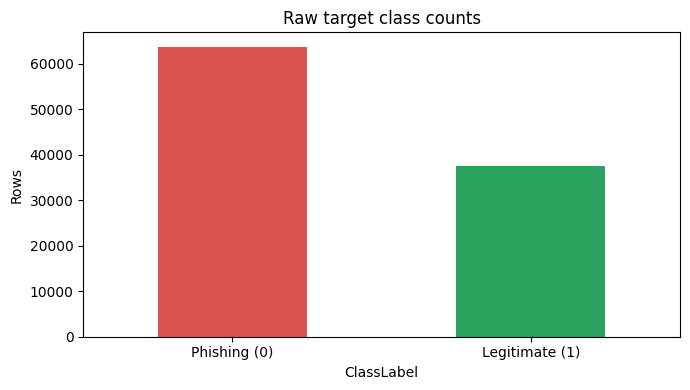

In [23]:
counts = df[TARGET_COL].value_counts().reindex([0,1])
ax = counts.plot(kind="bar", figsize=(7,4), color=["#d9534f","#2ca25f"], rot=0)
ax.set_xticklabels(["Phishing (0)","Legitimate (1)"]); ax.set_ylabel("Rows"); ax.set_title("Raw target class counts"); plt.tight_layout(); plt.show()

### 2.6 — Phishing Versus Legitimate Percentage Plot



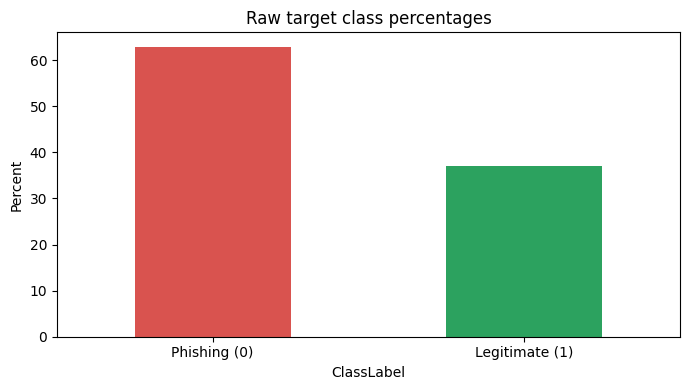

In [24]:
pct = df[TARGET_COL].value_counts(normalize=True).reindex([0,1])*100
ax = pct.plot(kind="bar", figsize=(7,4), color=["#d9534f","#2ca25f"], rot=0)
ax.set_xticklabels(["Phishing (0)","Legitimate (1)"]); ax.set_ylabel("Percent"); ax.set_title("Raw target class percentages"); plt.tight_layout(); plt.show()

### 2.7 — Feature Distribution Analysis



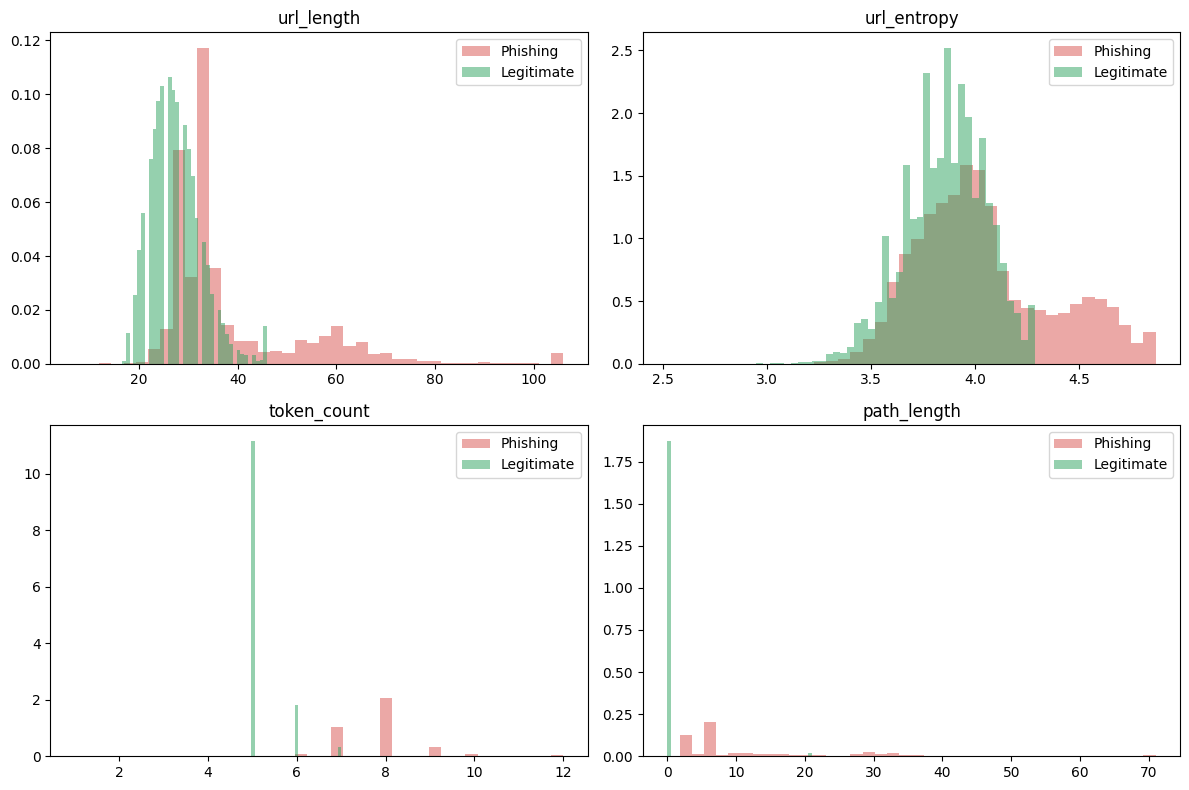

In [25]:
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax, feature in zip(axes.flat, ["url_length","url_entropy","token_count","path_length"]):
    for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
        vals = df.loc[df[TARGET_COL].eq(label),feature].dropna()
        vals = vals.clip(upper=vals.quantile(.99))
        ax.hist(vals,bins=40,alpha=.5,label=LABEL_MAP[label],color=color,density=True)
    ax.set_title(feature); ax.legend()
plt.tight_layout(); plt.show()

### 2.8 — URL Length Distribution



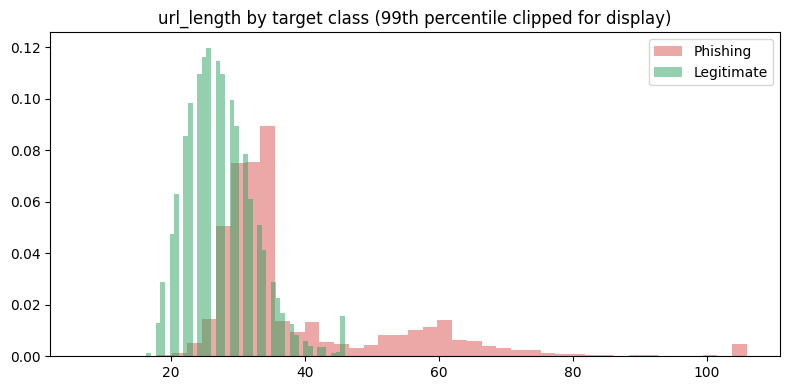

In [26]:
fig, ax = plt.subplots(figsize=(8,4))
for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
    vals = df.loc[df[TARGET_COL].eq(label),"url_length"].dropna()
    vals = vals.clip(upper=vals.quantile(.99))
    ax.hist(vals,bins=45,alpha=.5,density=True,label=LABEL_MAP[label],color=color)
ax.set_title("url_length by target class (99th percentile clipped for display)"); ax.legend(); plt.tight_layout(); plt.show()

### 2.9 — URL Entropy Distribution



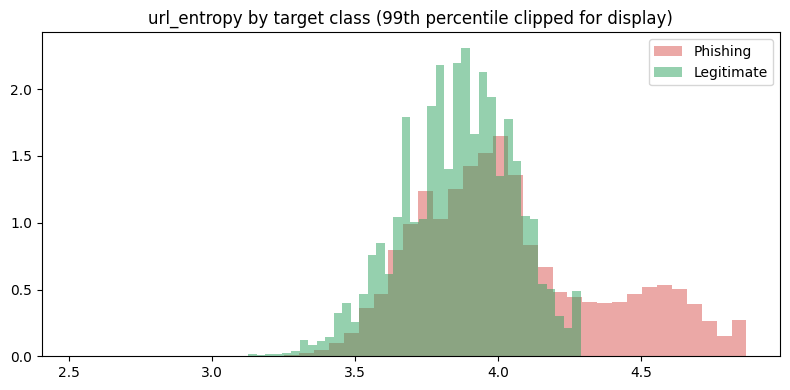

In [27]:
fig, ax = plt.subplots(figsize=(8,4))
for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
    vals = df.loc[df[TARGET_COL].eq(label),"url_entropy"].dropna()
    vals = vals.clip(upper=vals.quantile(.99))
    ax.hist(vals,bins=45,alpha=.5,density=True,label=LABEL_MAP[label],color=color)
ax.set_title("url_entropy by target class (99th percentile clipped for display)"); ax.legend(); plt.tight_layout(); plt.show()

### 2.10 — Token Count Distribution



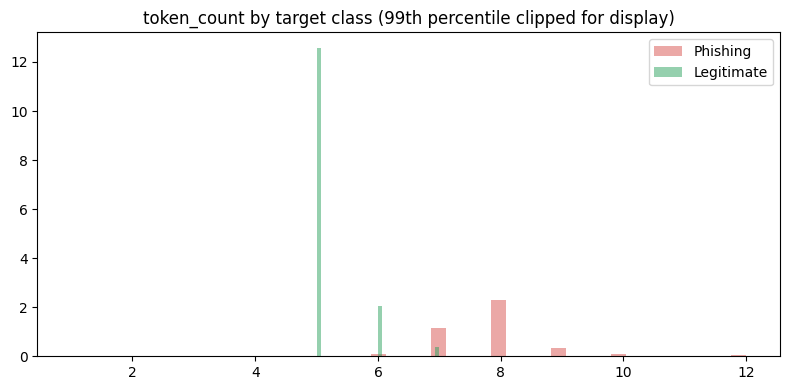

In [28]:
fig, ax = plt.subplots(figsize=(8,4))
for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
    vals = df.loc[df[TARGET_COL].eq(label),"token_count"].dropna()
    vals = vals.clip(upper=vals.quantile(.99))
    ax.hist(vals,bins=45,alpha=.5,density=True,label=LABEL_MAP[label],color=color)
ax.set_title("token_count by target class (99th percentile clipped for display)"); ax.legend(); plt.tight_layout(); plt.show()

### 2.11 — Subdomain Count Distribution



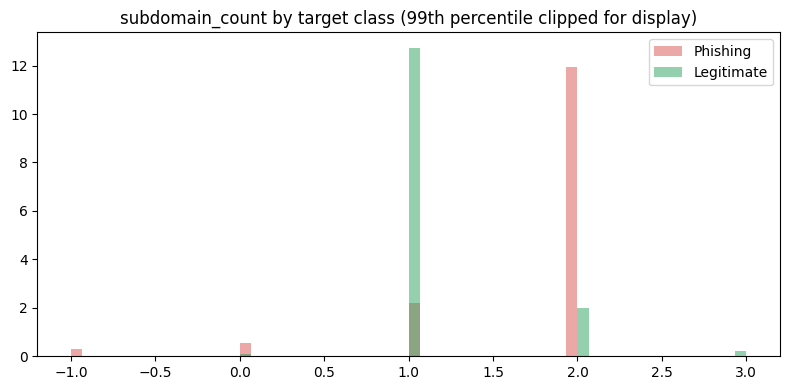

In [29]:
fig, ax = plt.subplots(figsize=(8,4))
for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
    vals = df.loc[df[TARGET_COL].eq(label),"subdomain_count"].dropna()
    vals = vals.clip(upper=vals.quantile(.99))
    ax.hist(vals,bins=45,alpha=.5,density=True,label=LABEL_MAP[label],color=color)
ax.set_title("subdomain_count by target class (99th percentile clipped for display)"); ax.legend(); plt.tight_layout(); plt.show()

### 2.12 — Query Parameter Distribution



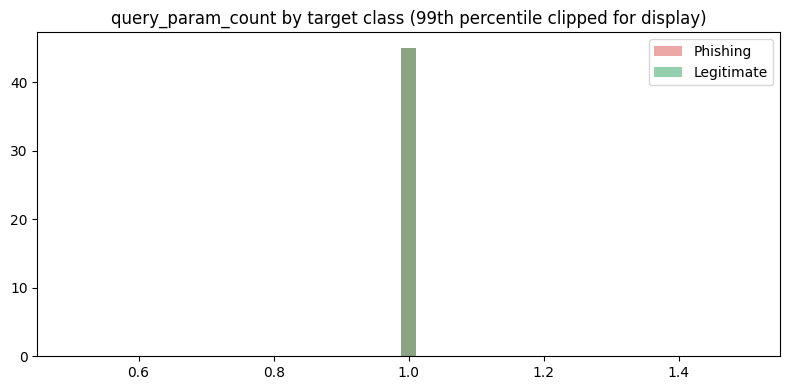

In [30]:
fig, ax = plt.subplots(figsize=(8,4))
for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
    vals = df.loc[df[TARGET_COL].eq(label),"query_param_count"].dropna()
    vals = vals.clip(upper=vals.quantile(.99))
    ax.hist(vals,bins=45,alpha=.5,density=True,label=LABEL_MAP[label],color=color)
ax.set_title("query_param_count by target class (99th percentile clipped for display)"); ax.legend(); plt.tight_layout(); plt.show()

### 2.13 — Numeric Character Distribution



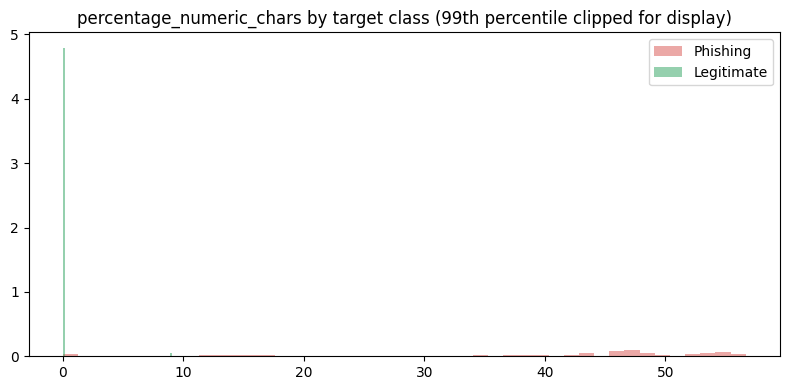

In [31]:
fig, ax = plt.subplots(figsize=(8,4))
for label,color in [(0,"#d9534f"),(1,"#2ca25f")]:
    vals = df.loc[df[TARGET_COL].eq(label),"percentage_numeric_chars"].dropna()
    vals = vals.clip(upper=vals.quantile(.99))
    ax.hist(vals,bins=45,alpha=.5,density=True,label=LABEL_MAP[label],color=color)
ax.set_title("percentage_numeric_chars by target class (99th percentile clipped for display)"); ax.legend(); plt.tight_layout(); plt.show()

### 2.14 — Correlation Matrix



In [32]:
corr = df[FEATURES+[TARGET_COL]].corr(numeric_only=True)
display(corr.round(2))

,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
url_length,1.00,-0.11,0.31,-0.22,0.72,0.66,-0.23,0.43,-0.16,0.88,0.07,0.44,0.01,0.47,0.12,0.01,-0.34
has_ip_address,-0.11,1.00,0.68,-0.78,-0.17,0.51,0.76,-0.05,0.82,-0.03,-0.21,0.73,-0.68,-0.11,-0.68,0.94,-0.74
dot_count,0.31,0.68,1.00,-0.70,0.23,0.80,0.60,0.09,0.50,0.38,-0.14,0.69,-0.61,0.21,-0.60,0.66,-0.69
https_flag,-0.22,-0.78,-0.70,1.00,-0.19,-0.68,-0.51,0.02,-0.64,-0.32,0.12,-0.73,0.61,-0.24,0.56,-0.83,0.93
url_entropy,0.72,-0.17,0.23,-0.19,1.00,0.48,-0.21,0.16,-0.23,0.67,0.12,0.17,0.11,0.61,0.24,-0.11,-0.29
token_count,0.66,0.51,0.80,-0.68,0.48,1.00,0.32,0.40,0.34,0.64,-0.11,0.73,-0.46,0.36,-0.45,0.57,-0.78
subdomain_count,-0.23,0.76,0.60,-0.51,-0.21,0.32,1.00,-0.11,0.63,-0.24,-0.15,0.49,-0.60,-0.07,-0.60,0.69,-0.44
query_param_count,0.43,-0.05,0.09,0.02,0.16,0.40,-0.11,1.00,-0.06,0.17,-0.01,0.29,0.03,0.03,-0.01,0.01,-0.04
tld_length,-0.16,0.82,0.50,-0.64,-0.23,0.34,0.63,-0.06,1.00,-0.18,-0.18,0.63,-0.48,-0.16,-0.51,0.85,-0.60
path_length,0.88,-0.03,0.38,-0.32,0.67,0.64,-0.24,0.17,-0.18,1.00,0.00,0.38,-0.07,0.51,-0.04,0.04,-0.42


### 2.15 — Correlation Heatmap



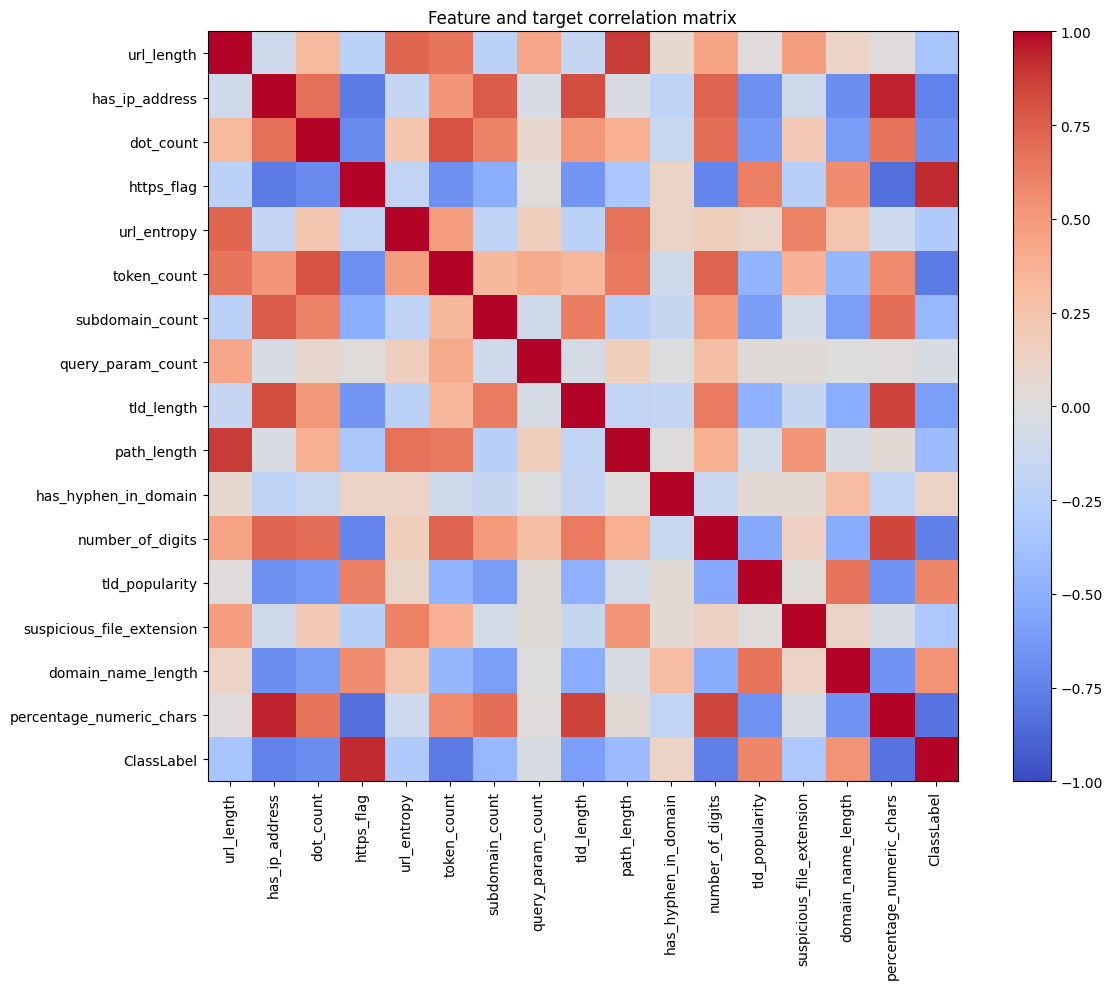

In [33]:
fig, ax = plt.subplots(figsize=(13,10))
img=ax.imshow(corr,cmap="coolwarm",vmin=-1,vmax=1); ax.set_xticks(range(len(corr.columns)),corr.columns,rotation=90); ax.set_yticks(range(len(corr.index)),corr.index); fig.colorbar(img,ax=ax); ax.set_title("Feature and target correlation matrix"); plt.tight_layout(); plt.show()

### 2.16 — Feature Relationship Analysis



In [34]:
class_means = df.groupby(TARGET_COL)[FEATURES].mean().T
class_means.columns = [LABEL_MAP.get(int(c),str(c)) for c in class_means.columns]
display(class_means.sort_values("Phishing",ascending=False))

,Phishing,Legitimate
url_length,39.411869,27.680874
percentage_numeric_chars,38.219915,0.247825
number_of_digits,13.477292,0.080767
path_length,13.284949,0.486787
token_count,7.882126,5.195631
tld_length,6.345331,2.726825
domain_name_length,4.114325,9.986308
url_entropy,4.044979,3.859295
dot_count,3.510270,2.155434
subdomain_count,1.721741,1.154928


### 2.17 — EDA Observations



In [35]:
# Inspect URL-shape diversity by class, not just row counts.
def _host_for_audit(u):
    try:
        return (urlparse(str(u) if "://" in str(u) else "http://"+str(u)).hostname or "").lower()
    except Exception:
        return ""
audit_df=df.dropna(subset=[TARGET_COL]).copy()
audit_df["_host"] = audit_df[URL_COL].map(_host_for_audit)
audit_df["_path_len"] = audit_df[URL_COL].map(lambda u: len(urlparse(str(u) if "://" in str(u) else "http://"+str(u)).path or ""))
audit_df["_query_present"] = audit_df[URL_COL].astype(str).str.contains(r"\?",regex=True)
rows=[]
for cls in [0,1]:
    part=audit_df[audit_df[TARGET_COL].eq(cls)]
    rows.append({"Class":LABEL_MAP[cls],"Rows":len(part),"Unique hostnames":part["_host"].nunique(),"Rows per hostname":len(part)/max(1,part["_host"].nunique()),"Median path length":part["_path_len"].median(),"90th pct path length":part["_path_len"].quantile(.90),"URLs with query %":100*part["_query_present"].mean()})
diversity_table=pd.DataFrame(rows).set_index("Class")
display(diversity_table.round(2))
print("Overall majority/minority row ratio:",round(audit_df[TARGET_COL].value_counts().max()/audit_df[TARGET_COL].value_counts().min(),3))
print("Row balance and structural diversity are different. Compare unique-host counts and path/query coverage before concluding that both classes are adequately represented.")

,Rows,Unique hostnames,Rows per hostname,Median path length,90th pct path length,URLs with query %
Class,,,,,,
Phishing,63678,26888,2.37,7.0,32.0,1.19
Legitimate,37540,37114,1.01,0.0,0.0,0.14


Overall majority/minority row ratio: 1.696
Row balance and structural diversity are different. Compare unique-host counts and path/query coverage before concluding that both classes are adequately represented.


### 2.18 — Phase 2 Summary



In [36]:
print("EDA completed. Key class counts:", df[TARGET_COL].value_counts().to_dict())
print("Use the class-conditional feature distributions above to interpret later false positives and false negatives.")

EDA completed. Key class counts: {0.0: 63678, 1.0: 37540}
Use the class-conditional feature distributions above to interpret later false positives and false negatives.


## PHASE 3 — DATA CLEANING AND DOMAIN-AWARE PREPROCESSING



### 3.1 — Phase 3 Introduction



In [37]:
print("Phase 3 objective: clean labels, create domain-separated train/validation/test partitions and prevent scaler leakage.")

Phase 3 objective: clean labels, create domain-separated train/validation/test partitions and prevent scaler leakage.


### 3.2 — Inspect Missing Values



In [38]:
print("Missing target values:", int(df[TARGET_COL].isna().sum()), "| Exact duplicate rows:", int(df.duplicated().sum()))

Missing target values: 1 | Exact duplicate rows: 346


### 3.3 — Handle Missing Target Values



In [39]:
df_clean = df.dropna(subset=[TARGET_COL]).copy()
df_clean[TARGET_COL] = pd.to_numeric(df_clean[TARGET_COL],errors="raise").astype(int)
assert set(df_clean[TARGET_COL].unique()) == {0,1}
print("Rows after removing missing target:",len(df_clean))

Rows after removing missing target: 101218


### 3.4 — Remove Duplicate Records



In [40]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)
print("Exact duplicates removed:",before-len(df_clean),"| Clean rows:",len(df_clean))

Exact duplicates removed: 346 | Clean rows: 100872


### 3.5 — Verify Cleaned Dataset



In [41]:
assert not df_clean.duplicated().any()
assert df_clean[FEATURES].notna().all().all(), "Feature columns contain missing values; inspect before modelling."
assert df_clean.groupby(URL_COL)[TARGET_COL].nunique().le(1).all()
print("Clean dataset verified:",df_clean.shape)
display(df_clean[TARGET_COL].value_counts().rename(index=LABEL_MAP).to_frame("Clean_count"))

Clean dataset verified: (100872, 18)


,Clean_count
ClassLabel,
Phishing,63492
Legitimate,37380


### 3.6 — Separate Input Features



In [42]:
X = df_clean[FEATURES].astype(float).copy()
print("X shape:",X.shape,"| feature order matches canonical list:",list(X.columns)==FEATURES)

X shape: (100872, 16) | feature order matches canonical list: True


### 3.7 — Separate Target Variable



In [43]:
y = df_clean[TARGET_COL].copy()
print("y shape:",y.shape,"| labels:",sorted(y.unique()))

y shape: (100872,) | labels: [np.int64(0), np.int64(1)]


### 3.8 — Verify Class Mapping



In [44]:
assert LABEL_MAP == {0:"Phishing",1:"Legitimate"}
print("Class mapping verified:",LABEL_MAP)
print("Phishing share:",round(y.eq(0).mean()*100,2),"% | Legitimate share:",round(y.eq(1).mean()*100,2),"%")

# Authoritative 16-feature extraction definitions, audited against the supplied CSV.
POPULAR_TLDS={"com","edu","gov","net","org"}
SUSPICIOUS_EXTENSIONS={"1exe","apk","bin","cmd","exe","js","zip"}
EXT_RX=re.compile(r"\.([A-Za-z0-9]{1,10})$")
IPV4_ANY_RX=re.compile(r"(?<!\d)(?:\d{1,3}\.){3}\d{1,3}(?!\d)")
TOKEN_SPLIT_RX=re.compile(r"[/.?=&]")
def shannon_entropy(text):
    if not text: return 0.0
    n=len(text)
    return float(-sum((count/n)*math.log2(count/n) for count in Counter(text).values()))
def extract_url_feature_dict(url):
    # Preserve raw urlparse behavior: adding a missing scheme changes source feature values.
    p=urlparse(url); host=p.hostname or ""; path=p.path or ""; query=p.query or ""
    host_parts=host.split(".")
    authority=p.netloc.rsplit("@",1)[-1]
    authority_last=authority.split(".")[-1] if authority else ""
    digits=sum(ch.isdigit() for ch in url); n=len(url)
    path_tail=path.rsplit("/",1)[-1].lower()
    ext_match=EXT_RX.search(path)
    path_ext=ext_match.group(1).lower() if ext_match else path_tail
    return {
        "url_length":float(n),"has_ip_address":float(int(bool(IPV4_ANY_RX.search(url)))),
        "dot_count":float(url.count(".")),"https_flag":float(int(url.startswith("https"))),
        "url_entropy":shannon_entropy(url),"token_count":float(len(TOKEN_SPLIT_RX.split(url))),
        "subdomain_count":float(len(host_parts)-2),"query_param_count":float(len(query.split("&"))),
        "tld_length":float(len(authority_last)),"path_length":float(len(path)),
        "has_hyphen_in_domain":float(int("-" in host)),"number_of_digits":float(digits),
        "tld_popularity":float(int(authority_last.lower() in POPULAR_TLDS)),
        "suspicious_file_extension":float(int(path_ext in SUSPICIOUS_EXTENSIONS or any(url.lower().endswith(ext) for ext in SUSPICIOUS_EXTENSIONS))),
        "domain_name_length":float(len(host_parts[-2]) if len(host_parts)>=2 else 0),
        "percentage_numeric_chars":float(digits/n*100 if n else 0),
    }
def extract_url_features(url):
    values=extract_url_feature_dict(url)
    return pd.DataFrame([[values[f] for f in FEATURES]],columns=FEATURES)
print("Shared training/deployment feature extractor defined.")

Class mapping verified: {0: 'Phishing', 1: 'Legitimate'}
Phishing share: 62.94 % | Legitimate share: 37.06 %
Shared training/deployment feature extractor defined.


### 3.9 — Extract Domain Information for Grouping



In [45]:
extractor = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=False)
def get_hostname(raw):
    try:
        text=str(raw).strip(); parsed=urlparse(text if "://" in text else "http://"+text)
        return (parsed.hostname or "").lower().rstrip(".") or None
    except Exception:
        return None
def registrable_domain(host):
    if not host: return None
    try:
        ipaddress.ip_address(host)
        return host
    except ValueError:
        pass
    ext=extractor(host)
    if ext.domain and ext.suffix:
        return f"{ext.domain}.{ext.suffix}"
    return host
hostnames=df_clean[URL_COL].map(get_hostname)
groups=hostnames.map(lambda h: registrable_domain(h) if h else None)
groups=groups.fillna("UNPARSED|"+df_clean[URL_COL].astype(str))
print("Unique hostnames:",hostnames.nunique(dropna=True),"| Unique registrable-domain groups:",groups.nunique())
domain_diversity=[]
for cls in [0,1]:
    mask=y.eq(cls)
    domain_diversity.append({"Class":LABEL_MAP[cls],"Rows":int(mask.sum()),"Unique hostnames":int(hostnames[mask].nunique()),"Unique registrable domains":int(groups[mask].nunique()),"Rows per registrable domain":float(mask.sum()/max(1,groups[mask].nunique()))})
display(pd.DataFrame(domain_diversity).set_index("Class").round(2))

Unique hostnames: 64001 | Unique registrable-domain groups: 62801


,Rows,Unique hostnames,Unique registrable domains,Rows per registrable domain
Class,,,,
Phishing,63492,26888,26252,2.42
Legitimate,37380,37114,36556,1.02


### 3.10 — Create Domain-Aware Train/Test Split



In [46]:
overall_phish=(y.eq(0).mean()*100)
outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
outer_splits=list(outer.split(X,y,groups))
outer_rows=[]
for i,(tr,te) in enumerate(outer_splits,1):
    test_ph=(y.iloc[te].eq(0).mean()*100)
    size_pct=len(te)/len(y)*100
    score=abs(size_pct-20)+abs(test_ph-overall_phish)
    outer_rows.append({"Fold":i,"Train_rows":len(tr),"Test_rows":len(te),"Test_%":size_pct,"Test_phishing_%":test_ph,"Selection_score":score})
outer_table=pd.DataFrame(outer_rows).set_index("Fold"); display(outer_table.round(2))
best_outer=int(outer_table.Selection_score.idxmin())
trainval_idx,test_idx=outer_splits[best_outer-1]
X_trainval,X_test=X.iloc[trainval_idx].copy(),X.iloc[test_idx].copy()
y_trainval,y_test=y.iloc[trainval_idx].copy(),y.iloc[test_idx].copy()
print("Chosen outer fold:",best_outer)

,Train_rows,Test_rows,Test_%,Test_phishing_%,Selection_score
Fold,,,,,
1,80469,20403,20.23,63.58,0.87
2,81197,19675,19.50,62.34,1.10
3,81067,19805,19.63,62.18,1.13
4,80633,20239,20.06,62.95,0.07
5,80122,20750,20.57,63.60,1.23


Chosen outer fold: 4


### 3.11 — Display Training and Testing Dimensions



In [47]:
inner=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE+1)
inner_groups=groups.iloc[trainval_idx].reset_index(drop=True)
inner_y=y_trainval.reset_index(drop=True)
inner_splits=list(inner.split(X_trainval.reset_index(drop=True),inner_y,inner_groups))
inner_rows=[]
for i,(tr,va) in enumerate(inner_splits,1):
    inner_rows.append({"Fold":i,"Train":len(tr),"Validation":len(va),"Validation_%":100*len(va)/len(inner_y),"Phishing_%":100*inner_y.iloc[va].eq(0).mean()})
inner_table=pd.DataFrame(inner_rows).set_index("Fold"); display(inner_table.round(2))
inner_overall_phish=inner_y.eq(0).mean()*100
inner_scores=[abs(100*len(va)/len(inner_y)-20)+abs(100*inner_y.iloc[va].eq(0).mean()-inner_overall_phish) for tr,va in inner_splits]
best_inner=int(np.argmin(inner_scores))
tr_rel,val_rel=inner_splits[best_inner]
X_train=X_trainval.iloc[tr_rel].copy(); y_train=y_trainval.iloc[tr_rel].copy()
X_val=X_trainval.iloc[val_rel].copy(); y_val=y_trainval.iloc[val_rel].copy()
print("Selected inner fold:",best_inner+1,"| Train/validation/test rows:",len(X_train),len(X_val),len(X_test))

,Train,Validation,Validation_%,Phishing_%
Fold,,,,
1,65463,15170,18.81,60.80
2,64433,16200,20.09,62.68
3,64030,16603,20.59,63.63
4,63868,16765,20.79,64.70
5,64738,15895,19.71,62.68


Selected inner fold: 2 | Train/validation/test rows: 64433 16200 20239


### 3.12 — Verify Class Distribution After Splitting



In [48]:
split_summary=pd.DataFrame({"Rows":[len(X_train),len(X_val),len(X_test)],"Phishing_%":[100*y_train.eq(0).mean(),100*y_val.eq(0).mean(),100*y_test.eq(0).mean()],"Legitimate_%":[100*y_train.eq(1).mean(),100*y_val.eq(1).mean(),100*y_test.eq(1).mean()]},index=["Train","Validation","Test"])
display(split_summary.round(2))

,Rows,Phishing_%,Legitimate_%
Train,64433,63.01,36.99
Validation,16200,62.68,37.32
Test,20239,62.95,37.05


### 3.13 — Fit StandardScaler on Training Data Only



In [49]:
scaler=StandardScaler()
scaler.fit(X_train)
print("Scaler fitted only on training rows:",len(X_train))
print("Scaler feature count:",len(scaler.mean_))

Scaler fitted only on training rows: 64433
Scaler feature count: 16


### 3.14 — Transform Training Data



In [50]:
X_train_scaled=pd.DataFrame(scaler.transform(X_train),columns=FEATURES,index=X_train.index)
print("Scaled training shape:",X_train_scaled.shape)

Scaled training shape: (64433, 16)


### 3.15 — Transform Testing Data



In [51]:
X_val_scaled=pd.DataFrame(scaler.transform(X_val),columns=FEATURES,index=X_val.index)
X_test_scaled=pd.DataFrame(scaler.transform(X_test),columns=FEATURES,index=X_test.index)
print("Validation shape:",X_val_scaled.shape,"| Test shape:",X_test_scaled.shape)

Validation shape: (16200, 16) | Test shape: (20239, 16)


### 3.16 — Verify Scaled Data



In [52]:
train_groups=set(groups.loc[X_train.index]); val_groups=set(groups.loc[X_val.index]); test_groups=set(groups.loc[X_test.index])
print("Train/validation overlap:",len(train_groups&val_groups))
print("Train/test overlap:",len(train_groups&test_groups))
print("Validation/test overlap:",len(val_groups&test_groups))
assert not (train_groups&val_groups or train_groups&test_groups or val_groups&test_groups), "Domain leakage detected."

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0


### 3.17 — Phase 3 Summary



In [53]:
print("PHASE 3 COMPLETE")
print("Grouped split sizes:",len(X_train),len(X_val),len(X_test))
print("Scaling leakage check passed; scaler saw training partition only.")

PHASE 3 COMPLETE
Grouped split sizes: 64433 16200 20239
Scaling leakage check passed; scaler saw training partition only.


## PHASE 4 — MODEL DEVELOPMENT



### 4.1 — Phase 4 Introduction



In [54]:
print("Phase 4 objective: compare original Logistic Regression, class-balanced Logistic Regression, Random Forest and XGBoost.")

Phase 4 objective: compare original Logistic Regression, class-balanced Logistic Regression, Random Forest and XGBoost.


### 4.2 — Import Model Libraries



In [55]:
from sklearn.ensemble import RandomForestClassifier
print("Algorithms imported. All candidates use the same domain-separated partitions.")

Algorithms imported. All candidates use the same domain-separated partitions.


### 4.3 — Configure Logistic Regression



In [56]:
LR_BASE_CONFIG={"penalty":"l2","C":1.0,"solver":"lbfgs","max_iter":1000,"random_state":RANDOM_STATE}
lr_base=LogisticRegression(**LR_BASE_CONFIG)
print("Baseline Logistic Regression:",LR_BASE_CONFIG)

Baseline Logistic Regression: {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000, 'random_state': 42}


### 4.4 — Train Logistic Regression



In [57]:
lr_base.fit(X_train_scaled,y_train)
print("Baseline Logistic Regression fitted.")

Baseline Logistic Regression fitted.


### 4.5 — Display Logistic Regression Configuration



In [58]:
LR_BALANCED_CONFIG={**LR_BASE_CONFIG,"class_weight":"balanced"}
lr_balanced=LogisticRegression(**LR_BALANCED_CONFIG)
print("Class-balanced LR config:",LR_BALANCED_CONFIG)

Class-balanced LR config: {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000, 'random_state': 42, 'class_weight': 'balanced'}


### 4.6 — Configure Random Forest



In [59]:
lr_balanced.fit(X_train_scaled,y_train)
print("Class-balanced Logistic Regression fitted.")

Class-balanced Logistic Regression fitted.


### 4.7 — Train Random Forest



In [60]:
rf_model=RandomForestClassifier(n_estimators=350,max_features="sqrt",min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE)
print(rf_model)

RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       n_estimators=350, n_jobs=-1, random_state=42)


### 4.8 — Display Random Forest Configuration



In [61]:
rf_model.fit(X_train,y_train)
print("Random Forest fitted on original-scale numeric features.")

Random Forest fitted on original-scale numeric features.


### 4.9 — Configure XGBoost



In [62]:
xgb_model=XGBClassifier(n_estimators=350,max_depth=6,learning_rate=0.05,subsample=0.85,colsample_bytree=0.85,reg_lambda=1.0,objective="binary:logistic",eval_metric="logloss",n_jobs=-1,random_state=RANDOM_STATE)
print("XGBoost configured.")

XGBoost configured.


### 4.10 — Train XGBoost



In [63]:
# Balanced sample weights; class 0 is phishing and class 1 is legitimate.
class_counts=y_train.value_counts(); n=len(y_train)
sample_weights=y_train.map({c:n/(2*count) for c,count in class_counts.items()}).to_numpy()
xgb_model.fit(X_train,y_train,sample_weight=sample_weights)
print("XGBoost fitted with balanced training sample weights.")

XGBoost fitted with balanced training sample weights.


### 4.11 — Display XGBoost Configuration



In [64]:
# Build controlled benign URL-structure augmentation using TRAINING-SPLIT legitimate domains only.
# This addresses a measured coverage gap: legitimate source URLs have very few non-empty paths/queries.
BENIGN_PATH_TEMPLATES=[
    "/docs/getting-started/overview","/articles/research-and-development/resources",
    "/learning/guides/introduction-to-data-science","/products/catalog/category/details",
    "/support/help-center/account-settings","/blog/2025/11/understanding-machine-learning",
    "/search?q=machine+learning&category=guide&page=2","/resources/downloads/documentation/index.html",
]
def make_benign_path_augmentation(url_series):
    seen=set(); rows=[]; synthetic_urls=[]
    for raw in url_series.astype(str):
        try: host=(urlparse(raw).hostname or "").lower()
        except Exception: host=""
        if not host or host in seen: continue
        seen.add(host)
        synthetic_url="https://"+host+BENIGN_PATH_TEMPLATES[(len(seen)-1)%len(BENIGN_PATH_TEMPLATES)]
        rows.append(extract_url_feature_dict(synthetic_url)); synthetic_urls.append(synthetic_url)
    return pd.DataFrame(rows,columns=FEATURES),synthetic_urls
train_legit_urls=df_clean.loc[y_train.index[y_train.eq(1)],URL_COL]
X_train_benign_aug,train_aug_urls=make_benign_path_augmentation(train_legit_urls)
y_train_benign_aug=pd.Series(1,index=range(len(X_train_benign_aug)),dtype=int)
X_train_aug=pd.concat([X_train.reset_index(drop=True),X_train_benign_aug],ignore_index=True)
y_train_aug=pd.concat([y_train.reset_index(drop=True),y_train_benign_aug],ignore_index=True)
scaler_aug=StandardScaler().fit(X_train_aug)
X_train_aug_scaled=scaler_aug.transform(X_train_aug)
lr_augmented=LogisticRegression(**LR_BASE_CONFIG).fit(X_train_aug_scaled,y_train_aug)
print("Unique training legitimate domains augmented:",len(X_train_benign_aug))
print("Original training rows:",len(X_train),"| Augmented training rows:",len(X_train_aug))
print("Synthetic variants are derived only from training-partition legitimate domains; validation/test domains are not used for fitting.")

candidate_models={"Logistic Regression C=1.0":lr_base,"Logistic Regression balanced":lr_balanced,"Logistic Regression + benign path augmentation":lr_augmented,"Random Forest":rf_model,"XGBoost":xgb_model}
print("Trained candidates:",list(candidate_models))

Unique training legitimate domains augmented: 23714
Original training rows: 64433 | Augmented training rows: 88147
Synthetic variants are derived only from training-partition legitimate domains; validation/test domains are not used for fitting.
Trained candidates: ['Logistic Regression C=1.0', 'Logistic Regression balanced', 'Logistic Regression + benign path augmentation', 'Random Forest', 'XGBoost']


### 4.12 — Store Trained Model References



In [65]:
# 4.12 — Store Trained Model References and Generate Validation Scores

def phishing_scores(model, X):
    """Return the model's phishing score (class 0), independent of class order."""
    if not hasattr(model, "predict_proba"):
        raise TypeError(f"{type(model).__name__} does not provide predict_proba().")

    classes = np.asarray(model.classes_)
    phishing_indices = np.flatnonzero(classes == 0)

    if len(phishing_indices) != 1:
        raise ValueError(
            f"Expected exactly one phishing class labelled 0; got classes {classes.tolist()}."
        )

    probabilities = model.predict_proba(X)

    if probabilities.ndim != 2 or probabilities.shape[1] != len(classes):
        raise ValueError("Unexpected predict_proba() output shape.")

    scores = probabilities[:, int(phishing_indices[0])]

    if not np.all(np.isfinite(scores)):
        raise ValueError("Model returned non-finite phishing scores.")

    return scores


val_scores = {
    "Logistic Regression C=1.0": phishing_scores(lr_base, X_val_scaled),
    "Logistic Regression balanced": phishing_scores(lr_balanced, X_val_scaled),
    "Logistic Regression + benign path augmentation": phishing_scores(
        lr_augmented, scaler_aug.transform(X_val)
    ),
    "Random Forest": phishing_scores(rf_model, X_val),
    "XGBoost": phishing_scores(xgb_model, X_val),
}

print("Validation scores generated for all five candidates.")
for model_name, scores in val_scores.items():
    print(f"{model_name}: {len(scores):,} validation scores")


Validation scores generated for all five candidates.
Logistic Regression C=1.0: 16,200 validation scores
Logistic Regression balanced: 16,200 validation scores
Logistic Regression + benign path augmentation: 16,200 validation scores
Random Forest: 16,200 validation scores
XGBoost: 16,200 validation scores


### 4.13 — Phase 4 Training Summary



In [66]:
print("PHASE 4 COMPLETE — all five candidates trained. No model has been selected using the test set.")


PHASE 4 COMPLETE — all five candidates trained. No model has been selected using the test set.


## PHASE 5 — MODEL EVALUATION



### 5.1 — Phase 5 Introduction



In [67]:
print("Phase 5 objective: evaluate validation and untouched test results with phishing treated as the positive class.")

Phase 5 objective: evaluate validation and untouched test results with phishing treated as the positive class.


### 5.2 — Generate Logistic Regression Predictions



In [68]:
res_2=evaluate_phishing(y_val,val_scores["Logistic Regression C=1.0"],FINAL_THRESHOLD)
print("Baseline Logistic Regression — validation results")
print({k:round(v,4) for k,v in res_2.items() if isinstance(v,(int,float,np.floating))})

Baseline Logistic Regression — validation results
{'Accuracy': 0.9972, 'Balanced Accuracy': np.float64(0.9975), 'Phishing Precision': 0.9992, 'Phishing Recall': 0.9963, 'Phishing F1': 0.9977, 'ROC-AUC': np.float64(0.9997), 'PR-AUC': np.float64(0.9996)}


### 5.3 — Generate Random Forest Predictions



In [69]:
res_3=evaluate_phishing(y_val,val_scores["Logistic Regression balanced"],FINAL_THRESHOLD)
print("Class-balanced Logistic Regression — validation results")
print({k:round(v,4) for k,v in res_3.items() if isinstance(v,(int,float,np.floating))})

Class-balanced Logistic Regression — validation results
{'Accuracy': 0.997, 'Balanced Accuracy': np.float64(0.9974), 'Phishing Precision': 0.9993, 'Phishing Recall': 0.9959, 'Phishing F1': 0.9976, 'ROC-AUC': np.float64(0.9995), 'PR-AUC': np.float64(0.9995)}


### 5.4 — Generate XGBoost Predictions



In [70]:
res_4=evaluate_phishing(y_val,val_scores["Random Forest"],FINAL_THRESHOLD)
print("Random Forest — validation results")
print({k:round(v,4) for k,v in res_4.items() if isinstance(v,(int,float,np.floating))})

Random Forest — validation results
{'Accuracy': 0.9975, 'Balanced Accuracy': np.float64(0.9969), 'Phishing Precision': 0.9966, 'Phishing Recall': 0.9995, 'Phishing F1': 0.998, 'ROC-AUC': np.float64(1.0), 'PR-AUC': np.float64(1.0)}


### 5.5 — Calculate Logistic Regression Accuracy



In [71]:
res_5=evaluate_phishing(y_val,val_scores["XGBoost"],FINAL_THRESHOLD)
print("XGBoost — validation results")
print({k:round(v,4) for k,v in res_5.items() if isinstance(v,(int,float,np.floating))})

XGBoost — validation results
{'Accuracy': 0.9991, 'Balanced Accuracy': np.float64(0.999), 'Phishing Precision': 0.9991, 'Phishing Recall': 0.9994, 'Phishing F1': 0.9993, 'ROC-AUC': np.float64(1.0), 'PR-AUC': np.float64(1.0)}


### 5.6 — Calculate Random Forest Accuracy



In [72]:
res_6=evaluate_phishing(y_val,val_scores["Logistic Regression + benign path augmentation"],FINAL_THRESHOLD)
print("Augmented Logistic Regression — validation results")
print({k:round(v,4) for k,v in res_6.items() if isinstance(v,(int,float,np.floating))})

Augmented Logistic Regression — validation results
{'Accuracy': 0.9955, 'Balanced Accuracy': np.float64(0.9964), 'Phishing Precision': 0.9999, 'Phishing Recall': 0.9929, 'Phishing F1': 0.9964, 'ROC-AUC': np.float64(0.9978), 'PR-AUC': np.float64(0.9991)}


### 5.7 — Calculate XGBoost Accuracy



In [73]:
validation_metrics={name:evaluate_phishing(y_val,score,FINAL_THRESHOLD) for name,score in val_scores.items()}
validation_table=pd.DataFrame({name:{k:v for k,v in result.items() if isinstance(v,(int,float,np.floating))} for name,result in validation_metrics.items()}).T
display(validation_table.style.format("{:.4f}"))

,Accuracy,Balanced Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC,PR-AUC
Logistic Regression C=1.0,0.9972,0.9975,0.9992,0.9963,0.9977,0.9997,0.9996
Logistic Regression balanced,0.9970,0.9974,0.9993,0.9959,0.9976,0.9995,0.9995
Logistic Regression + benign path augmentation,0.9955,0.9964,0.9999,0.9929,0.9964,0.9978,0.9991
Random Forest,0.9975,0.9969,0.9966,0.9995,0.9980,1.0000,1.0000
XGBoost,0.9991,0.9990,0.9991,0.9994,0.9993,1.0000,1.0000


### 5.8 — Calculate Precision, Recall and F1



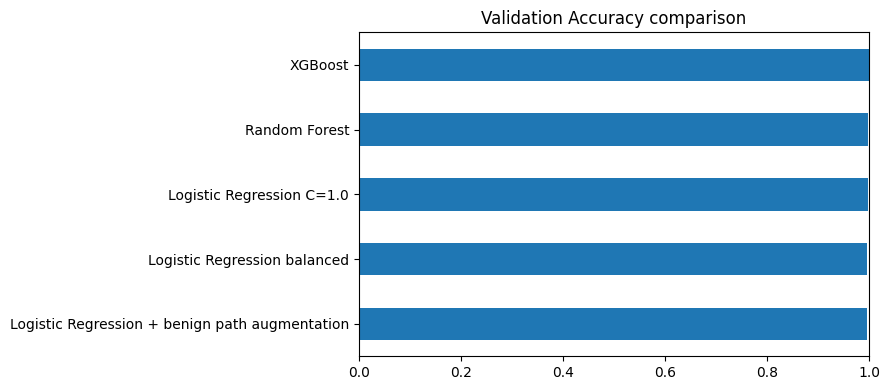

In [74]:
fig,ax=plt.subplots(figsize=(9,4)); validation_table["Accuracy"].sort_values().plot(kind="barh",ax=ax); ax.set_title("Validation Accuracy comparison"); ax.set_xlim(0,1); plt.tight_layout(); plt.show()

### 5.9 — Calculate ROC-AUC



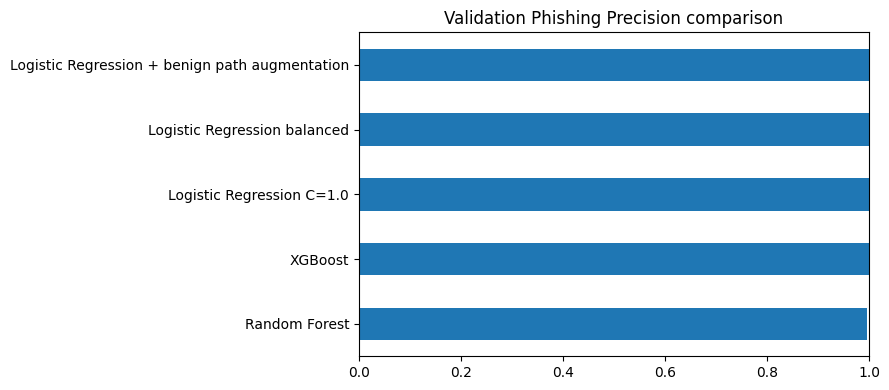

In [75]:
fig,ax=plt.subplots(figsize=(9,4)); validation_table["Phishing Precision"].sort_values().plot(kind="barh",ax=ax); ax.set_title("Validation Phishing Precision comparison"); ax.set_xlim(0,1); plt.tight_layout(); plt.show()

### 5.10 — Calculate PR-AUC Where Supported



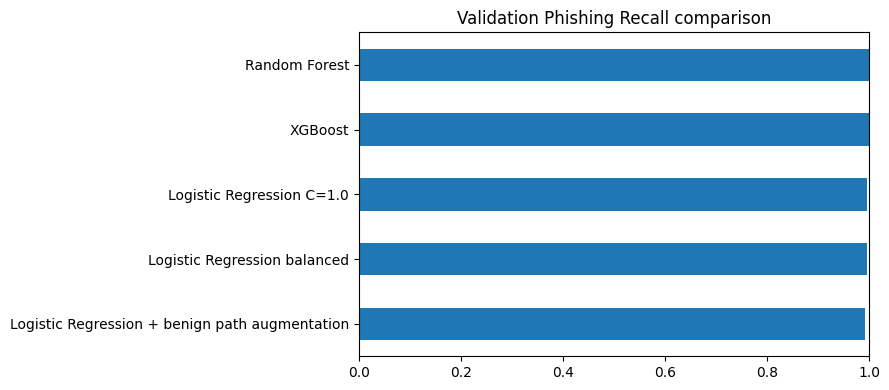

In [76]:
fig,ax=plt.subplots(figsize=(9,4)); validation_table["Phishing Recall"].sort_values().plot(kind="barh",ax=ax); ax.set_title("Validation Phishing Recall comparison"); ax.set_xlim(0,1); plt.tight_layout(); plt.show()

### 5.11 — Logistic Regression Classification Report



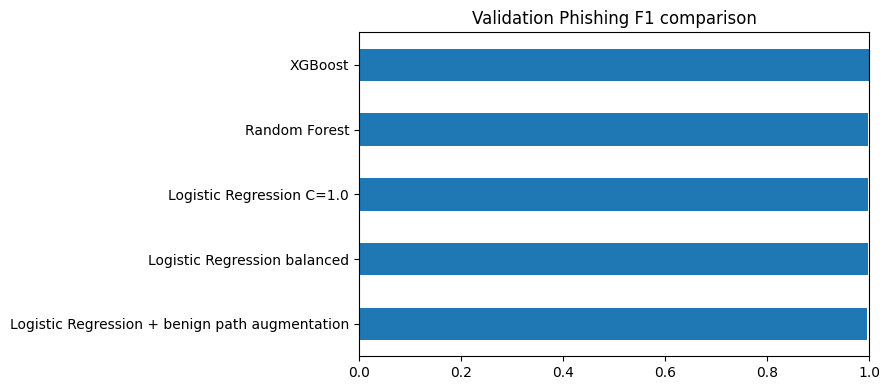

In [77]:
fig,ax=plt.subplots(figsize=(9,4)); validation_table["Phishing F1"].sort_values().plot(kind="barh",ax=ax); ax.set_title("Validation Phishing F1 comparison"); ax.set_xlim(0,1); plt.tight_layout(); plt.show()

### 5.12 — Random Forest Classification Report



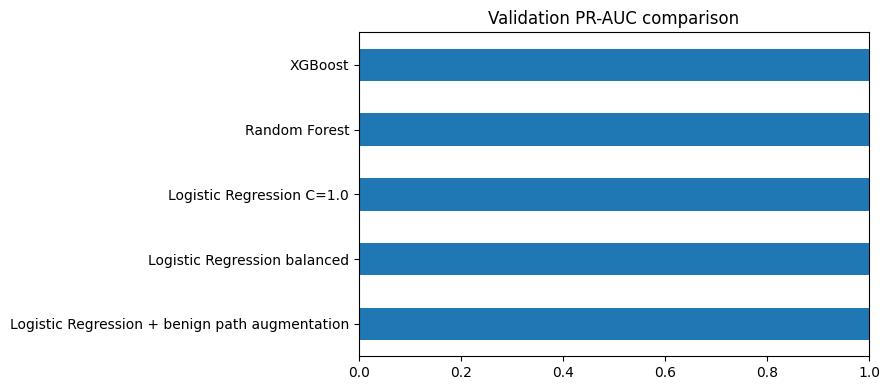

In [78]:
fig,ax=plt.subplots(figsize=(9,4)); validation_table["PR-AUC"].sort_values().plot(kind="barh",ax=ax); ax.set_title("Validation PR-AUC comparison"); ax.set_xlim(0,1); plt.tight_layout(); plt.show()

### 5.13 — XGBoost Classification Report



In [79]:
for name,result in validation_metrics.items():
    print("\n",name,"\n",classification_report(y_val,result["Predictions"],labels=[0,1],target_names=["Phishing","Legitimate"],zero_division=0,digits=3))


 Logistic Regression C=1.0 
               precision    recall  f1-score   support

    Phishing      0.999     0.996     0.998     10154
  Legitimate      0.994     0.999     0.996      6046

    accuracy                          0.997     16200
   macro avg      0.996     0.997     0.997     16200
weighted avg      0.997     0.997     0.997     16200


 Logistic Regression balanced 
               precision    recall  f1-score   support

    Phishing      0.999     0.996     0.998     10154
  Legitimate      0.993     0.999     0.996      6046

    accuracy                          0.997     16200
   macro avg      0.996     0.997     0.997     16200
weighted avg      0.997     0.997     0.997     16200


 Logistic Regression + benign path augmentation 
               precision    recall  f1-score   support

    Phishing      1.000     0.993     0.996     10154
  Legitimate      0.988     1.000     0.994      6046

    accuracy                          0.995     16200
   macro avg  

### 5.14 — Logistic Regression Confusion Matrix



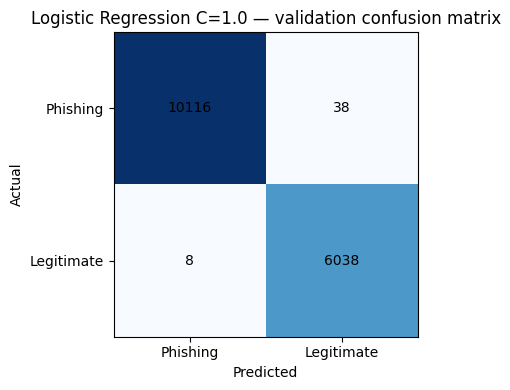

In [80]:
cm=validation_metrics["Logistic Regression C=1.0"]["Confusion Matrix"]
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm,cmap="Blues"); ax.set_title("Logistic Regression C=1.0 — validation confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_xticks([0,1],["Phishing","Legitimate"]); ax.set_yticks([0,1],["Phishing","Legitimate"])
for i in range(2):
    for j in range(2): ax.text(j,i,int(cm[i,j]),ha="center",va="center")
plt.tight_layout(); plt.show()

### 5.15 — Random Forest Confusion Matrix



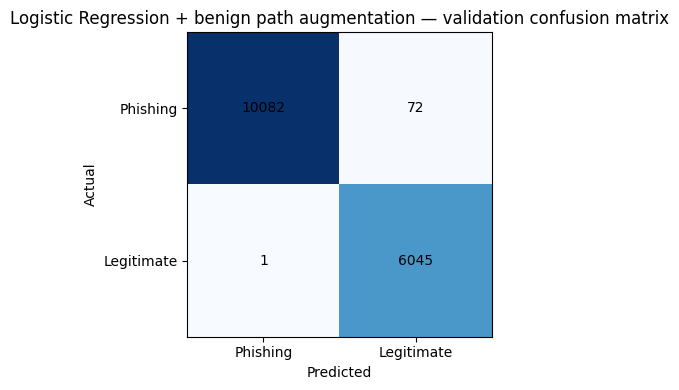

In [81]:
cm=validation_metrics["Logistic Regression + benign path augmentation"]["Confusion Matrix"]
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm,cmap="Blues"); ax.set_title("Logistic Regression + benign path augmentation — validation confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_xticks([0,1],["Phishing","Legitimate"]); ax.set_yticks([0,1],["Phishing","Legitimate"])
for i in range(2):
    for j in range(2): ax.text(j,i,int(cm[i,j]),ha="center",va="center")
plt.tight_layout(); plt.show()

### 5.16 — XGBoost Confusion Matrix



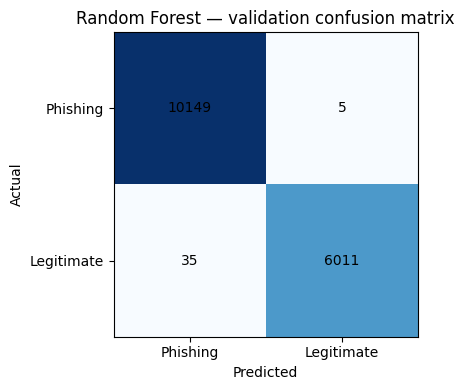

In [82]:
cm=validation_metrics["Random Forest"]["Confusion Matrix"]
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm,cmap="Blues"); ax.set_title("Random Forest — validation confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_xticks([0,1],["Phishing","Legitimate"]); ax.set_yticks([0,1],["Phishing","Legitimate"])
for i in range(2):
    for j in range(2): ax.text(j,i,int(cm[i,j]),ha="center",va="center")
plt.tight_layout(); plt.show()

### 5.17 — Evaluation Comparison



In [83]:
print("Validation error counts for baseline LR:",validation_metrics["Logistic Regression C=1.0"]["Confusion Matrix"].tolist())
print("Validation error counts for augmented LR:",validation_metrics["Logistic Regression + benign path augmentation"]["Confusion Matrix"].tolist())
print("Confusion matrix convention: rows actual [Phishing, Legitimate], columns predicted [Phishing, Legitimate].")

Validation error counts for baseline LR: [[10116, 38], [8, 6038]]
Validation error counts for augmented LR: [[10082, 72], [1, 6045]]
Confusion matrix convention: rows actual [Phishing, Legitimate], columns predicted [Phishing, Legitimate].


### 5.18 — Phase 5 Summary



In [84]:
print("PHASE 5 COMPLETE — all five candidates evaluated on held-out validation domains at the fixed 50% threshold.")

PHASE 5 COMPLETE — all five candidates evaluated on held-out validation domains at the fixed 50% threshold.


## PHASE 5A — TRAINING VS. HELD-OUT PERFORMANCE

This diagnostic compares the three core algorithms on the training, validation and untouched test partitions. It uses the existing fitted models and existing preprocessing only. No model is retrained, no scaler is refitted, and the test set is not used for model selection.

Phishing (class 0) is treated as the positive class. The fixed project threshold is retained.

In [85]:
# PHASE 5A — TRAINING VS. HELD-OUT PERFORMANCE (diagnostic only)
import hashlib

p5a_models = {
    "Logistic Regression": (lr_base, X_train_scaled, X_val_scaled, X_test_scaled),
    "Random Forest": (rf_model, X_train, X_val, X_test),
    "XGBoost": (xgb_model, X_train, X_val, X_test),
}
p5a_targets = {"Train": y_train, "Validation": y_val, "Test": y_test}
p5a_rows = []
p5a_snapshots = {}

for p5a_name, (p5a_model, p5a_train_X, p5a_val_X, p5a_test_X) in p5a_models.items():
    p5a_inputs = {"Train": p5a_train_X, "Validation": p5a_val_X, "Test": p5a_test_X}
    for p5a_split, p5a_X in p5a_inputs.items():
        p5a_scores = phishing_scores(p5a_model, p5a_X)
        p5a_metrics = evaluate_phishing(p5a_targets[p5a_split], p5a_scores, FINAL_THRESHOLD)
        p5a_rows.append({
            "Model": p5a_name,
            "Partition": p5a_split,
            "Rows": len(p5a_targets[p5a_split]),
            "Accuracy": p5a_metrics["Accuracy"],
            "Phishing Precision": p5a_metrics["Phishing Precision"],
            "Phishing Recall": p5a_metrics["Phishing Recall"],
            "Phishing F1": p5a_metrics["Phishing F1"],
            "ROC-AUC": p5a_metrics["ROC-AUC"],
            "PR-AUC": p5a_metrics["PR-AUC"],
        })
        if p5a_split == "Test":
            p5a_snapshots[p5a_name] = (
                np.asarray(p5a_metrics["Predictions"]).copy(),
                np.asarray(p5a_scores).copy()
            )

p5a_performance = pd.DataFrame(p5a_rows)
display(p5a_performance.set_index(["Model", "Partition"]).round(4))

p5a_gap_rows = []
for p5a_name in p5a_models:
    p5a_train_row = p5a_performance.query("Model == @p5a_name and Partition == 'Train'").iloc[0]
    p5a_test_row = p5a_performance.query("Model == @p5a_name and Partition == 'Test'").iloc[0]
    p5a_gap_rows.append({
        "Model": p5a_name,
        "Training Accuracy": p5a_train_row["Accuracy"],
        "Test Accuracy": p5a_test_row["Accuracy"],
        "Accuracy Gap (Train - Test)": p5a_train_row["Accuracy"] - p5a_test_row["Accuracy"],
        "Training Phishing F1": p5a_train_row["Phishing F1"],
        "Test Phishing F1": p5a_test_row["Phishing F1"],
        "Phishing F1 Gap (Train - Test)": p5a_train_row["Phishing F1"] - p5a_test_row["Phishing F1"],
    })
p5a_gap_table = pd.DataFrame(p5a_gap_rows).set_index("Model")
display(p5a_gap_table.round(4))

print("Interpretation guide: a large positive train-test gap can indicate overfitting.")
print("These gaps are diagnostic; they do not by themselves prove the cause of a performance difference.")
print("The existing models, scaler, validation/test partitions and Phase 5 results have not been modified.")

Rows  Accuracy  Phishing Precision  Phishing Recall  Phishing F1  ROC-AUC  PR-AUC
Model               Partition                                                                                     
Logistic Regression Train       64433    0.9971              0.9990           0.9964       0.9977   0.9998  0.9999
                    Validation  16200    0.9972              0.9992           0.9963       0.9977   0.9997  0.9996
                    Test        20239    0.9960              0.9971           0.9965       0.9968   0.9999  0.9999
Random Forest       Train       64433    0.9999              0.9999           1.0000       0.9999   1.0000  1.0000
                    Validation  16200    0.9975              0.9966           0.9995       0.9980   1.0000  1.0000
                    Test        20239    0.9976              0.9963           0.9999       0.9981   1.0000  1.0000
XGBoost             Train       64433    1.0000              1.0000           1.0000       1.0000   1.0000  1.0000
                    Validation  16200    0.9991              0.9991           0.9994       0.9993   1.0000  1.0000
                    Test        20239    0.9978              0.9966           0.9998       0.9982   1.0000  1.0000

,Training Accuracy,Test Accuracy,Accuracy Gap (Train - Test),Training Phishing F1,Test Phishing F1,Phishing F1 Gap (Train - Test)
Model,,,,,,
Logistic Regression,0.9971,0.9960,0.0011,0.9977,0.9968,0.0009
Random Forest,0.9999,0.9976,0.0022,0.9999,0.9981,0.0018
XGBoost,1.0000,0.9978,0.0022,1.0000,0.9982,0.0017


Interpretation guide: a large positive train-test gap can indicate overfitting.
These gaps are diagnostic; they do not by themselves prove the cause of a performance difference.
The existing models, scaler, validation/test partitions and Phase 5 results have not been modified.


## PHASE 5B — INDEPENDENT EXTERNAL DATASET EVALUATION (PhiUSIIL)

This section evaluates the **existing Logistic Regression, Random Forest and XGBoost models** on the independently published PhiUSIIL Phishing URL Dataset (UCI Machine Learning Repository, dataset 967).

- Dataset labels: `0 = Phishing`, `1 = Legitimate` (same convention as this project).
- Features are regenerated using the project's existing `extract_url_feature_dict()` function and canonical `FEATURES` order.
- The existing StandardScaler is used with `transform()` only for Logistic Regression.
- No model is fitted, no scaler is refitted, and no threshold is tuned on this dataset.
- Exact URL duplicates and registered domains already present in the original dataset are identified. Results are shown for the filtered external set and the stricter domain-disjoint subset.
- This is an external benchmark evaluation, not proof of performance on every live phishing campaign. Dataset differences and feature coverage limitations must be considered when interpreting results.

If automatic download is unavailable, the cell asks for the PhiUSIIL ZIP or CSV to be uploaded in Colab.

In [86]:
# PHASE 5B — INDEPENDENT EXTERNAL DATASET EVALUATION (PhiUSIIL)
# This cell only transforms external data and predicts with existing fitted models.
import io
import zipfile
import urllib.request
import hashlib
from urllib.parse import urlsplit

p5b_dataset_url = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
p5b_dataset_page = "https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset"
p5b_url_col, p5b_label_col = "URL", "label"

# Snapshot the original modelling objects and held-out test predictions before external evaluation.
p5b_original_df_hash = hashlib.md5(
    pd.util.hash_pandas_object(df_clean, index=True).values.tobytes()
).hexdigest()
p5b_original_scaler_mean = scaler.mean_.copy()
p5b_original_model_ids = {
    "Logistic Regression": id(lr_base),
    "Random Forest": id(rf_model),
    "XGBoost": id(xgb_model),
}
p5b_original_test_hashes = {}
for p5b_name, p5b_pred_score in p5a_snapshots.items():
    p5b_original_test_hashes[p5b_name] = (
        hashlib.md5(np.asarray(p5b_pred_score[0]).tobytes()).hexdigest(),
        hashlib.md5(np.asarray(p5b_pred_score[1]).tobytes()).hexdigest()
    )

print("Dataset: PhiUSIIL Phishing URL Dataset (UCI dataset 967)")
print("Source:", p5b_dataset_page)
try:
    p5b_request = urllib.request.Request(
        p5b_dataset_url, headers={"User-Agent": "Mozilla/5.0"}
    )
    p5b_raw_bytes = urllib.request.urlopen(p5b_request, timeout=300).read()
    p5b_source_description = "Downloaded from the UCI Machine Learning Repository"
except Exception as p5b_download_error:
    print("Automatic download failed:", repr(p5b_download_error))
    print("Upload the PhiUSIIL dataset ZIP or CSV file to continue.")
    try:
        from google.colab import files
        p5b_uploaded = files.upload()
        if not p5b_uploaded:
            raise RuntimeError("No dataset file was uploaded.")
        p5b_uploaded_name = next(iter(p5b_uploaded))
        p5b_raw_bytes = p5b_uploaded[p5b_uploaded_name]
        p5b_source_description = "Uploaded file: " + p5b_uploaded_name
    except Exception as p5b_upload_error:
        raise RuntimeError(
            "PhiUSIIL data is required. Download the UCI dataset ZIP/CSV and upload it in Colab."
        ) from p5b_upload_error

if p5b_raw_bytes[:2] == b"PK":
    with zipfile.ZipFile(io.BytesIO(p5b_raw_bytes)) as p5b_zip:
        p5b_csv_names = [n for n in p5b_zip.namelist() if n.lower().endswith(".csv")]
        if not p5b_csv_names:
            raise ValueError("The uploaded/downloaded ZIP contains no CSV file.")
        p5b_csv_name = max(p5b_csv_names, key=lambda n: p5b_zip.getinfo(n).file_size)
        with p5b_zip.open(p5b_csv_name) as p5b_csv_file:
            p5b_external_raw = pd.read_csv(p5b_csv_file, low_memory=False)
else:
    p5b_external_raw = pd.read_csv(io.BytesIO(p5b_raw_bytes), low_memory=False)

print("Source:", p5b_source_description)
print("Raw external dataset shape:", p5b_external_raw.shape)
if p5b_url_col not in p5b_external_raw.columns or p5b_label_col not in p5b_external_raw.columns:
    raise ValueError(
        f"Expected columns '{p5b_url_col}' and '{p5b_label_col}'. "
        f"Available columns: {list(p5b_external_raw.columns)}"
    )

# Keep only rows with a URL and a valid binary label; do not silently remap unknown labels.
p5b_external = p5b_external_raw[[p5b_url_col, p5b_label_col]].copy()
p5b_external[p5b_url_col] = p5b_external[p5b_url_col].astype("string").str.strip()
p5b_external[p5b_label_col] = pd.to_numeric(p5b_external[p5b_label_col], errors="coerce")
p5b_external = p5b_external.dropna(subset=[p5b_url_col, p5b_label_col])
p5b_external = p5b_external[
    p5b_external[p5b_url_col].ne("") &
    p5b_external[p5b_label_col].isin([0, 1])
].copy()
p5b_external[p5b_label_col] = p5b_external[p5b_label_col].astype(int)
p5b_external = p5b_external.drop_duplicates(subset=[p5b_url_col]).reset_index(drop=True)

if set(p5b_external[p5b_label_col].unique()) != {0, 1}:
    raise ValueError("External dataset must contain both labels 0 (Phishing) and 1 (Legitimate).")

print("Usable unique external URLs:", f"{len(p5b_external):,}")
display(
    p5b_external[p5b_label_col].value_counts()
    .rename(index={0: "Phishing (0)", 1: "Legitimate (1)"})
    .to_frame("Rows")
)

# Recreate the exact 16 project features in the same order used for training.
p5b_feature_rows = []
p5b_feature_errors = []
for p5b_idx, p5b_url in enumerate(p5b_external[p5b_url_col].astype(str)):
    try:
        p5b_feature_rows.append(extract_url_feature_dict(p5b_url))
    except Exception as p5b_feature_error:
        p5b_feature_rows.append(None)
        p5b_feature_errors.append((p5b_idx, str(p5b_feature_error)))

p5b_feature_ok = np.array([row is not None for row in p5b_feature_rows], dtype=bool)
p5b_external = p5b_external.loc[p5b_feature_ok].reset_index(drop=True)
p5b_external_X = pd.DataFrame(
    [row for row in p5b_feature_rows if row is not None],
    columns=FEATURES
).astype(float)
p5b_external_y = p5b_external[p5b_label_col].astype(int).reset_index(drop=True)

if list(p5b_external_X.columns) != list(FEATURES):
    raise AssertionError("External feature order does not match the trained feature order.")
if p5b_external_X.isna().any().any() or not np.isfinite(p5b_external_X.to_numpy()).all():
    raise ValueError("External feature matrix contains missing or non-finite values.")
if len(p5b_external_X) == 0:
    raise ValueError("No external URLs could be converted into the project's 16 features.")

print("Feature matrix:", p5b_external_X.shape)
print("Feature order exact match:", list(p5b_external_X.columns) == list(FEATURES))
print("Feature extraction failures:", len(p5b_feature_errors))
print("External phishing share (%):", round(100 * p5b_external_y.eq(0).mean(), 2))
print("External legitimate share (%):", round(100 * p5b_external_y.eq(1).mean(), 2))

# Identify overlap using normalized URL strings and registered domains.
def p5b_normalize_url(value):
    return str(value).strip().lower().rstrip("/")

p5b_original_urls = df_clean[URL_COL].astype(str)
p5b_original_normalized = set(p5b_original_urls.map(p5b_normalize_url))
p5b_external_normalized = p5b_external[ p5b_url_col ].astype(str).map(p5b_normalize_url)
p5b_exact_overlap = p5b_external_normalized.isin(p5b_original_normalized)

p5b_original_domains = set()
for p5b_url in p5b_original_urls:
    p5b_host = get_hostname(p5b_url)
    p5b_domain = registrable_domain(p5b_host) if p5b_host else None
    if p5b_domain:
        p5b_original_domains.add(p5b_domain)

p5b_external_domains = []
for p5b_url in p5b_external[p5b_url_col].astype(str):
    p5b_host = get_hostname(p5b_url)
    p5b_external_domains.append(registrable_domain(p5b_host) if p5b_host else None)
p5b_external_domains = pd.Series(p5b_external_domains, index=p5b_external.index, dtype="object")
p5b_domain_overlap = p5b_external_domains.isin(p5b_original_domains)
p5b_group_a_mask = ~p5b_exact_overlap
p5b_group_b_mask = p5b_group_a_mask & ~p5b_domain_overlap

p5b_overlap_summary = pd.DataFrame({
    "Check": ["Exact normalized URL overlap", "Registered-domain overlap"],
    "External rows affected": [
        int(p5b_exact_overlap.sum()),
        int(p5b_domain_overlap.sum())
    ],
    "External share (%)": [
        round(100 * p5b_exact_overlap.mean(), 3),
        round(100 * p5b_domain_overlap.mean(), 3)
    ]
}).set_index("Check")
display(p5b_overlap_summary)

# Evaluate the three original core algorithms only. Threshold remains the project's fixed 0.50.
p5b_model_inputs = {
    "Logistic Regression": (lr_base, scaler.transform(p5b_external_X)),
    "Random Forest": (rf_model, p5b_external_X),
    "XGBoost": (xgb_model, p5b_external_X),
}
p5b_external_results = []
p5b_external_confusion = {}

for p5b_group_name, p5b_mask in [
    ("Group A — exact-URL overlap removed", p5b_group_a_mask),
    ("Group B — exact URL and domain overlap removed", p5b_group_b_mask),
]:
    p5b_count = int(p5b_mask.sum())
    p5b_y_group = p5b_external_y.loc[p5b_mask].to_numpy()
    if p5b_count == 0 or len(np.unique(p5b_y_group)) < 2:
        print(f"{p5b_group_name}: skipped; no rows or only one class remains.")
        continue

    for p5b_model_name, (p5b_model, p5b_all_input) in p5b_model_inputs.items():
        p5b_X_group = p5b_all_input[p5b_mask.to_numpy()]
        p5b_score = phishing_scores(p5b_model, p5b_X_group)
        p5b_metric = evaluate_phishing(p5b_y_group, p5b_score, FINAL_THRESHOLD)
        p5b_external_results.append({
            "Evaluation Group": p5b_group_name,
            "Model": p5b_model_name,
            "Rows": p5b_count,
            "Phishing Rows": int((p5b_y_group == 0).sum()),
            "Legitimate Rows": int((p5b_y_group == 1).sum()),
            "Accuracy": p5b_metric["Accuracy"],
            "Balanced Accuracy": p5b_metric["Balanced Accuracy"],
            "Phishing Precision": p5b_metric["Phishing Precision"],
            "Phishing Recall": p5b_metric["Phishing Recall"],
            "Phishing F1": p5b_metric["Phishing F1"],
            "ROC-AUC": p5b_metric["ROC-AUC"],
            "PR-AUC": p5b_metric["PR-AUC"],
        })
        p5b_external_confusion[(p5b_group_name, p5b_model_name)] = p5b_metric["Confusion Matrix"]

p5b_external_metrics = pd.DataFrame(p5b_external_results)
if p5b_external_metrics.empty:
    raise ValueError("No valid external evaluation group remained after overlap filtering.")
display(p5b_external_metrics.set_index(["Evaluation Group", "Model"]).round(4))

for (p5b_group_name, p5b_model_name), p5b_cm in p5b_external_confusion.items():
    print(f"\n{p5b_model_name} — {p5b_group_name}")
    display(pd.DataFrame(
        p5b_cm,
        index=["Actual Phishing", "Actual Legitimate"],
        columns=["Predicted Phishing", "Predicted Legitimate"]
    ))

# Compare strict external results with the existing original held-out test metrics.
p5b_comparison_rows = []
for p5b_model_name in p5a_models:
    p5b_original_test = p5a_performance.query(
        "Model == @p5b_model_name and Partition == 'Test'"
    ).iloc[0]
    p5b_strict_rows = p5b_external_metrics[
        (p5b_external_metrics["Model"] == p5b_model_name) &
        (p5b_external_metrics["Evaluation Group"] == "Group B — exact URL and domain overlap removed")
    ]
    if len(p5b_strict_rows):
        p5b_external_row = p5b_strict_rows.iloc[0]
        p5b_comparison_rows.append({
            "Model": p5b_model_name,
            "Original Test Accuracy": p5b_original_test["Accuracy"],
            "External Accuracy": p5b_external_row["Accuracy"],
            "Accuracy Change": p5b_external_row["Accuracy"] - p5b_original_test["Accuracy"],
            "Original Test Phishing F1": p5b_original_test["Phishing F1"],
            "External Phishing F1": p5b_external_row["Phishing F1"],
            "Phishing F1 Change": p5b_external_row["Phishing F1"] - p5b_original_test["Phishing F1"],
            "Original Test ROC-AUC": p5b_original_test["ROC-AUC"],
            "External ROC-AUC": p5b_external_row["ROC-AUC"],
        })
if p5b_comparison_rows:
    p5b_generalization_comparison = pd.DataFrame(p5b_comparison_rows).set_index("Model")
    display(p5b_generalization_comparison.round(4))
else:
    print("Strict domain-disjoint group was unavailable; no direct generalisation-gap table was produced.")

# Integrity checks: external evaluation must not change original data, models, scaler or stored test outputs.
assert hashlib.md5(
    pd.util.hash_pandas_object(df_clean, index=True).values.tobytes()
).hexdigest() == p5b_original_df_hash, "Original training dataframe changed."
assert np.array_equal(scaler.mean_, p5b_original_scaler_mean), "Original scaler changed."
assert {
    "Logistic Regression": id(lr_base),
    "Random Forest": id(rf_model),
    "XGBoost": id(xgb_model),
} == p5b_original_model_ids, "An original model reference changed."
for p5b_name, p5b_pred_score in p5a_snapshots.items():
    p5b_now_hashes = (
        hashlib.md5(np.asarray(p5b_pred_score[0]).tobytes()).hexdigest(),
        hashlib.md5(np.asarray(p5b_pred_score[1]).tobytes()).hexdigest()
    )
    assert p5b_now_hashes == p5b_original_test_hashes[p5b_name]
print("Integrity checks passed: original data, models, scaler and stored test snapshots remain unchanged.")
print("External evaluation complete. No model fitting, scaler fitting or threshold tuning was performed.")

Dataset: PhiUSIIL Phishing URL Dataset (UCI dataset 967)
Source: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset
Source: Downloaded from the UCI Machine Learning Repository
Raw external dataset shape: (235795, 56)
Usable unique external URLs: 235,370


,Rows
label,
Legitimate (1),134850
Phishing (0),100520


Feature matrix: (235370, 16)
Feature order exact match: True
Feature extraction failures: 0
External phishing share (%): 42.71
External legitimate share (%): 57.29


,External rows affected,External share (%)
Check,,
Exact normalized URL overlap,36944,15.696
Registered-domain overlap,67528,28.690


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Rows  Phishing Rows  Legitimate Rows  Accuracy  Balanced Accuracy  Phishing Precision  Phishing Recall  \
Evaluation Group                               Model                                                                                                                           
Group A — exact-URL overlap removed            Logistic Regression  198426         100520            97906    0.9081             0.9093              0.9999           0.8186   
                                               Random Forest        198426         100520            97906    0.7849             0.7877              1.0000           0.5754   
                                               XGBoost              198426         100520            97906    0.7786             0.7814              1.0000           0.5629   
Group B — exact URL and domain overlap removed Logistic Regression  167842          71836            96006    0.9395             0.9293              0.9999           0.8586   
                                               Random Forest        167842          71836            96006    0.7655             0.7260              1.0000           0.4520   
                                               XGBoost              167842          71836            96006    0.7596             0.7191              1.0000           0.4382   

                                                                    Phishing F1  ROC-AUC  PR-AUC  
Evaluation Group                               Model                                              
Group A — exact-URL overlap removed            Logistic Regression       0.9002   0.9907  0.9938  
                                               Random Forest             0.7305   0.9972  0.9976  
                                               XGBoost                   0.7203   0.9976  0.9984  
Group B — exact URL and domain overlap removed Logistic Regression       0.9239   0.9918  0.9929  
                                               Random Forest             0.6226   0.9963  0.9963  
                                               XGBoost                   0.6094   0.9969  0.9973

... (10 outputs left out)


XGBoost — Group B — exact URL and domain overlap removed


,Predicted Phishing,Predicted Legitimate
Actual Phishing,31481,40355
Actual Legitimate,0,96006


,Original Test Accuracy,External Accuracy,Accuracy Change,Original Test Phishing F1,External Phishing F1,Phishing F1 Change,Original Test ROC-AUC,External ROC-AUC
Model,,,,,,,,
Logistic Regression,0.9960,0.9395,-0.0565,0.9968,0.9239,-0.0729,0.9999,0.9918
Random Forest,0.9976,0.7655,-0.2322,0.9981,0.6226,-0.3755,1.0000,0.9963
XGBoost,0.9978,0.7596,-0.2382,0.9982,0.6094,-0.3888,1.0000,0.9969


Integrity checks passed: original data, models, scaler and stored test snapshots remain unchanged.
External evaluation complete. No model fitting, scaler fitting or threshold tuning was performed.


## PHASE 6 — MODEL COMPARISON AND ERROR ANALYSIS



### 6.1 — Phase 6 Introduction



In [87]:
print("Phase 6 objective: compare candidates using validation only, select the Logistic Regression variant without test leakage, then assess the held-out test set once.")

Phase 6 objective: compare candidates using validation only, select the Logistic Regression variant without test leakage, then assess the held-out test set once.


### 6.2 — Create Model Comparison DataFrame



In [88]:
# Build a separate structural stress test from VALIDATION legitimate domains only.
val_legit_urls=df_clean.loc[y_val.index[y_val.eq(1)],URL_COL]
X_val_benign_challenge,validation_challenge_urls=make_benign_path_augmentation(val_legit_urls)
print("Held-out validation legitimate domains in structural challenge:",len(X_val_benign_challenge))
challenge_scores={
    "Logistic Regression C=1.0":phishing_scores(lr_base,scaler.transform(X_val_benign_challenge)),
    "Logistic Regression balanced":phishing_scores(lr_balanced,scaler.transform(X_val_benign_challenge)),
    "Logistic Regression + benign path augmentation":phishing_scores(lr_augmented,scaler_aug.transform(X_val_benign_challenge)),
}
challenge_fpr={name:float(np.mean(score>=FINAL_THRESHOLD)) for name,score in challenge_scores.items()}
validation_table["Synthetic benign path FPR"] = pd.Series(challenge_fpr)
validation_table["Deployment validation score"] = 0.5*validation_table["Phishing F1"]+0.5*(1-validation_table["Synthetic benign path FPR"])
display(validation_table.sort_values("Deployment validation score",ascending=False).round(4))
print("Caution: generated benign paths are a controlled stress test, not independently verified live URLs or a replacement for a labelled external benchmark.")

Held-out validation legitimate domains in structural challenge: 5942


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


,Accuracy,Balanced Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC,PR-AUC,Synthetic benign path FPR,Deployment validation score
Logistic Regression + benign path augmentation,0.9955,0.9964,0.9999,0.9929,0.9964,0.9978,0.9991,0.0002,0.9981
Logistic Regression balanced,0.9970,0.9974,0.9993,0.9959,0.9976,0.9995,0.9995,0.2014,0.8981
Logistic Regression C=1.0,0.9972,0.9975,0.9992,0.9963,0.9977,0.9997,0.9996,0.4704,0.7637
Random Forest,0.9975,0.9969,0.9966,0.9995,0.9980,1.0000,1.0000,NaN,NaN
XGBoost,0.9991,0.9990,0.9991,0.9994,0.9993,1.0000,1.0000,NaN,NaN


Caution: generated benign paths are a controlled stress test, not independently verified live URLs or a replacement for a labelled external benchmark.


### 6.3 — Display Comparison Table



In [89]:
display(validation_table[["Phishing F1","Phishing Recall","PR-AUC","Synthetic benign path FPR","Deployment validation score"]].sort_values("Deployment validation score",ascending=False).round(4))

,Phishing F1,Phishing Recall,PR-AUC,Synthetic benign path FPR,Deployment validation score
Logistic Regression + benign path augmentation,0.9964,0.9929,0.9991,0.0002,0.9981
Logistic Regression balanced,0.9976,0.9959,0.9995,0.2014,0.8981
Logistic Regression C=1.0,0.9977,0.9963,0.9996,0.4704,0.7637
Random Forest,0.9980,0.9995,1.0000,NaN,NaN
XGBoost,0.9993,0.9994,1.0000,NaN,NaN


### 6.4 — Accuracy Comparison Graph



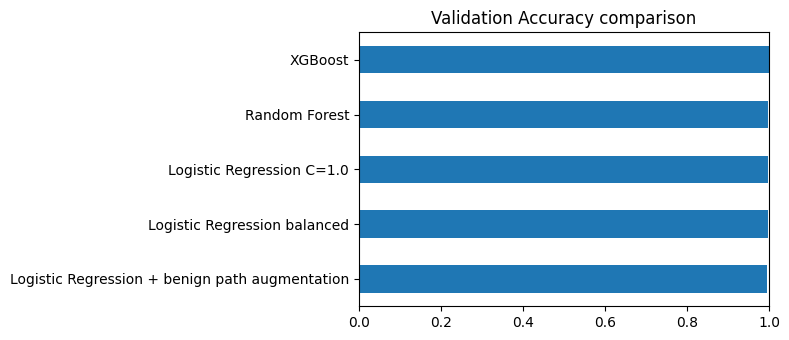

In [90]:
fig,ax=plt.subplots(figsize=(8,3.5)); validation_table["Accuracy"].sort_values().plot(kind="barh",ax=ax); ax.set_xlim(0,1); ax.set_title("Validation Accuracy comparison"); plt.tight_layout(); plt.show()

### 6.5 — Precision Comparison Graph



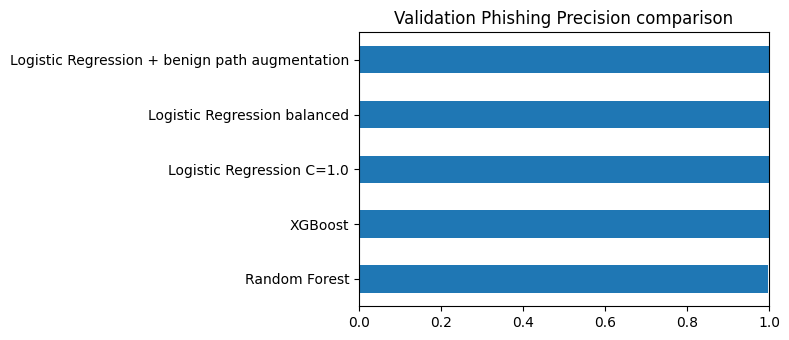

In [91]:
fig,ax=plt.subplots(figsize=(8,3.5)); validation_table["Phishing Precision"].sort_values().plot(kind="barh",ax=ax); ax.set_xlim(0,1); ax.set_title("Validation Phishing Precision comparison"); plt.tight_layout(); plt.show()

### 6.6 — Recall Comparison Graph



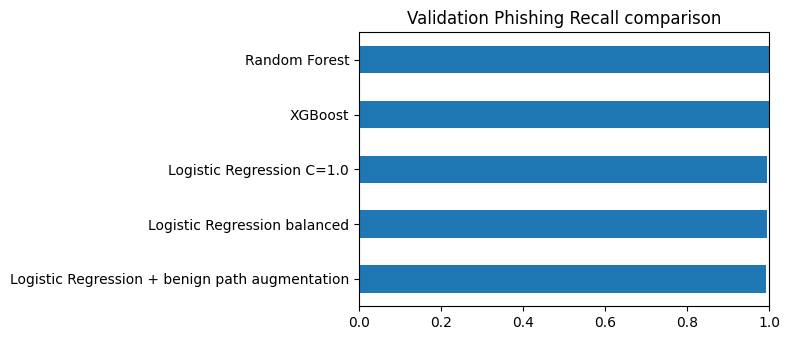

In [92]:
fig,ax=plt.subplots(figsize=(8,3.5)); validation_table["Phishing Recall"].sort_values().plot(kind="barh",ax=ax); ax.set_xlim(0,1); ax.set_title("Validation Phishing Recall comparison"); plt.tight_layout(); plt.show()

### 6.7 — F1-Score Comparison Graph



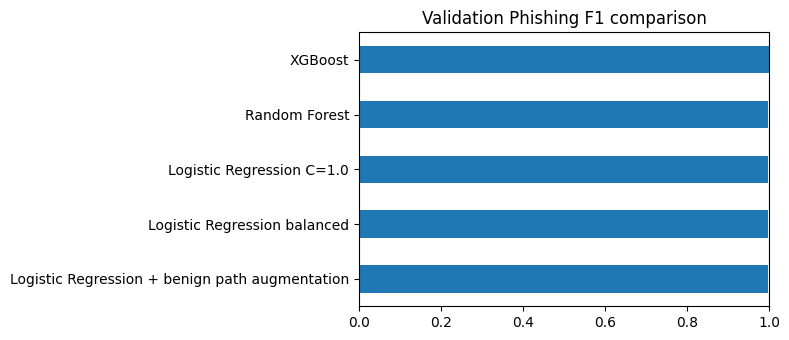

In [93]:
fig,ax=plt.subplots(figsize=(8,3.5)); validation_table["Phishing F1"].sort_values().plot(kind="barh",ax=ax); ax.set_xlim(0,1); ax.set_title("Validation Phishing F1 comparison"); plt.tight_layout(); plt.show()

### 6.8 — ROC-AUC Comparison Graph



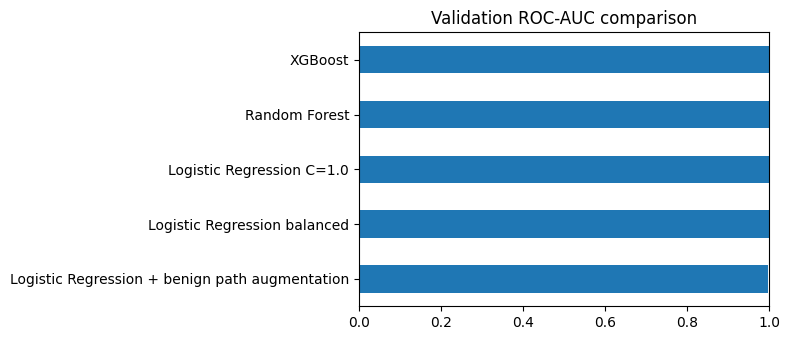

In [94]:
fig,ax=plt.subplots(figsize=(8,3.5)); validation_table["ROC-AUC"].sort_values().plot(kind="barh",ax=ax); ax.set_xlim(0,1); ax.set_title("Validation ROC-AUC comparison"); plt.tight_layout(); plt.show()

### 6.9 — False Positive Analysis



In [95]:
base_cm=validation_metrics["Logistic Regression C=1.0"]["Confusion Matrix"]
print("False positives:",int(base_cm[1,0]),"| False negatives:",int(base_cm[0,1]))
print("False positives are legitimate URLs incorrectly flagged as phishing; false negatives are phishing URLs missed by the detector.")

False positives: 8 | False negatives: 38
False positives are legitimate URLs incorrectly flagged as phishing; false negatives are phishing URLs missed by the detector.


### 6.10 — False Negative Analysis



In [96]:
print("False-negative rate for phishing:",round(base_cm[0,1]/max(1,base_cm[0].sum()),4))
print("False-positive rate for legitimate:",round(base_cm[1,0]/max(1,base_cm[1].sum()),4))

False-negative rate for phishing: 0.0037
False-positive rate for legitimate: 0.0013


### 6.11 — Generalisation Discussion



In [97]:
print("Generalisation checks: domain groups are disjoint across partitions; validation/test are not random URL-row splits. This is stricter than a row-wise split and reduces memorisation of repeated domains.")

Generalisation checks: domain groups are disjoint across partitions; validation/test are not random URL-row splits. This is stricter than a row-wise split and reduces memorisation of repeated domains.


### 6.12 — Explain Final Logistic Regression Selection



In [98]:
lr_candidates=["Logistic Regression C=1.0","Logistic Regression balanced","Logistic Regression + benign path augmentation"]
selected_lr_name=max(lr_candidates,key=lambda name:validation_table.loc[name,"Deployment validation score"])
selected_lr_config=LR_BALANCED_CONFIG if selected_lr_name=="Logistic Regression balanced" else LR_BASE_CONFIG
print("Selected deployment candidate:",selected_lr_name)
print("Selection uses validation phishing F1 and a separate held-out-domain benign path stress test; the test set is not used.")

Selected deployment candidate: Logistic Regression + benign path augmentation
Selection uses validation phishing F1 and a separate held-out-domain benign path stress test; the test set is not used.


### 6.13 — Phase 6 Summary



In [99]:
print("PHASE 6 COMPLETE — selected Logistic Regression candidate:",selected_lr_name)
print("Selection was made without examining the held-out test set. The 50% decision threshold remains fixed.")

PHASE 6 COMPLETE — selected Logistic Regression candidate: Logistic Regression + benign path augmentation
Selection was made without examining the held-out test set. The 50% decision threshold remains fixed.


## PHASE 7 — FINAL MODEL SELECTION AND ARTIFACT VERIFICATION



### 7.1 — Phase 7 Introduction



In [100]:
print("Phase 7 objective: refit the selected Logistic Regression on train + validation, evaluate untouched test domains and persist exact deployment artifacts.")

Phase 7 objective: refit the selected Logistic Regression on train + validation, evaluate untouched test domains and persist exact deployment artifacts.


### 7.2 — Identify Final Logistic Regression



In [101]:
# Refit selected LR on train + validation. If augmentation won validation selection,
# regenerate benign path variants using only train+validation legitimate domains.
X_trainval_final=pd.concat([X_train,X_val]).sort_index()
y_trainval_final=pd.concat([y_train,y_val]).sort_index()
if selected_lr_name=="Logistic Regression + benign path augmentation":
    fit_legit_urls=df_clean.loc[y_trainval_final.index[y_trainval_final.eq(1)],URL_COL]
    X_final_benign_aug,final_aug_urls=make_benign_path_augmentation(fit_legit_urls)
    X_fit_final=pd.concat([X_trainval_final.reset_index(drop=True),X_final_benign_aug],ignore_index=True)
    y_fit_final=pd.concat([y_trainval_final.reset_index(drop=True),pd.Series(1,index=range(len(X_final_benign_aug)),dtype=int)],ignore_index=True)
else:
    X_fit_final=X_trainval_final.reset_index(drop=True)
    y_fit_final=y_trainval_final.reset_index(drop=True)
final_scaler=StandardScaler().fit(X_fit_final)
final_model=LogisticRegression(**selected_lr_config).fit(final_scaler.transform(X_fit_final),y_fit_final)
X_test_final_scaled=final_scaler.transform(X_test[FEATURES])
print("Final model:",selected_lr_name)
print("Real training rows:",len(X_trainval_final),"| Synthetic benign augmentation rows:",len(X_fit_final)-len(X_trainval_final))
print("Test domains remain completely excluded from fitting.")

Final model: Logistic Regression + benign path augmentation
Real training rows: 80633 | Synthetic benign augmentation rows: 29656
Test domains remain completely excluded from fitting.


### 7.3 — Verify Model Hyperparameters



In [102]:
print("Final model:",final_model)
print("Hyperparameters:",final_model.get_params())

Final model: LogisticRegression(max_iter=1000, random_state=42)
Hyperparameters: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


### 7.4 — Verify Class Mapping



In [103]:
print("Model classes:",final_model.classes_)
assert set(final_model.classes_)=={0,1}
print("Class 0 = Phishing; class 1 = Legitimate")

Model classes: [0 1]
Class 0 = Phishing; class 1 = Legitimate


### 7.5 — Verify the 16-Feature Schema



In [104]:
assert len(FEATURES)==16 and set(FEATURES).issubset(X_trainval_final.columns)
print("Feature count:",len(FEATURES))

Feature count: 16


### 7.6 — Verify Feature Order



In [105]:
assert list(X_trainval_final.columns)==FEATURES
print("Feature order:",FEATURES)

Feature order: ['url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars']


### 7.7 — Save Model Artifact



In [106]:
import joblib
MODEL_PATH="phishguard_final_lr_model.joblib"
joblib.dump(final_model,MODEL_PATH)
print("Saved:",MODEL_PATH)

Saved: phishguard_final_lr_model.joblib


### 7.8 — Save Fitted Scaler Artifact



In [107]:
SCALER_PATH="phishguard_final_lr_scaler.joblib"
joblib.dump(final_scaler,SCALER_PATH)
print("Saved:",SCALER_PATH)

Saved: phishguard_final_lr_scaler.joblib


### 7.9 — Save Feature List Artifact



In [108]:
FEATURE_PATH="phishguard_final_lr_features.joblib"
joblib.dump(FEATURES,FEATURE_PATH)
print("Saved:",FEATURE_PATH)

Saved: phishguard_final_lr_features.joblib


### 7.10 — Save Configuration Artifact



In [109]:
CONFIG_PATH="phishguard_final_lr_config.joblib"
model_config={"project":"PhishGuard","selected_candidate":selected_lr_name,"hyperparameters":selected_lr_config,"feature_order":FEATURES,"target_mapping":{"0":"Phishing","1":"Legitimate"},"threshold":FINAL_THRESHOLD,"random_state":RANDOM_STATE,"group_split":"StratifiedGroupKFold by registrable domain","benign_path_augmentation":bool(selected_lr_name=="Logistic Regression + benign path augmentation"),"augmentation_rows":int(len(X_fit_final)-len(X_trainval_final))}
joblib.dump(model_config,CONFIG_PATH)
print("Saved:",CONFIG_PATH)

Saved: phishguard_final_lr_config.joblib


### 7.11 — Reload Model Artifact



In [110]:
loaded_model=joblib.load(MODEL_PATH)
assert hasattr(loaded_model,"predict_proba")
print("Reloaded model classes:",loaded_model.classes_)

Reloaded model classes: [0 1]


### 7.12 — Reload Scaler Artifact



In [111]:
loaded_scaler=joblib.load(SCALER_PATH)
assert len(loaded_scaler.mean_)==16
print("Reloaded scaler feature count:",len(loaded_scaler.mean_))

Reloaded scaler feature count: 16


### 7.13 — Reload Feature List and Configuration



In [112]:
loaded_features=joblib.load(FEATURE_PATH)
loaded_config=joblib.load(CONFIG_PATH)
assert loaded_features==FEATURES and loaded_config["feature_order"]==FEATURES
print("Feature list and configuration reloaded successfully.")

Feature list and configuration reloaded successfully.


### 7.14 — Verify Model Integrity



In [113]:
assert list(loaded_model.classes_)==list(final_model.classes_)
assert np.allclose(loaded_scaler.mean_,final_scaler.mean_)
print("Model/scaler integrity checks passed.")

Model/scaler integrity checks passed.


### 7.15 — Compare Predictions Before and After Reload



In [114]:
before=final_model.predict_proba(X_test_final_scaled)
after=loaded_model.predict_proba(loaded_scaler.transform(X_test[loaded_features]))
assert np.allclose(before,after,atol=1e-12)
print("Before/after reload predictions match exactly within tolerance.")

Before/after reload predictions match exactly within tolerance.


### 7.16 — Phase 7 Summary



In [115]:
final_test_scores=phishing_scores(loaded_model,loaded_scaler.transform(X_test[loaded_features]))
final_test_metrics=evaluate_phishing(y_test,final_test_scores,FINAL_THRESHOLD)
print("FINAL HELD-OUT TEST METRICS")
print({k:round(v,4) for k,v in final_test_metrics.items() if isinstance(v,(int,float,np.floating))})
print(classification_report(y_test,final_test_metrics["Predictions"],labels=[0,1],target_names=["Phishing","Legitimate"],zero_division=0,digits=4))
print("Confusion matrix [actual rows; predicted columns]:\n",final_test_metrics["Confusion Matrix"])

FINAL HELD-OUT TEST METRICS
{'Accuracy': 0.9932, 'Balanced Accuracy': np.float64(0.9937), 'Phishing Precision': 0.9973, 'Phishing Recall': 0.9919, 'Phishing F1': 0.9946, 'ROC-AUC': np.float64(0.9984), 'PR-AUC': np.float64(0.9994)}
              precision    recall  f1-score   support

    Phishing     0.9973    0.9919    0.9946     12740
  Legitimate     0.9864    0.9955    0.9909      7499

    accuracy                         0.9932     20239
   macro avg     0.9919    0.9937    0.9928     20239
weighted avg     0.9933    0.9932    0.9932     20239

Confusion matrix [actual rows; predicted columns]:
 [[12637   103]
 [   34  7465]]


## PHASE 8 — FINAL PREDICTION SYSTEM AND INTERACTIVE UI



### 8.1 — Phase 8 Introduction and Deployment Overview



In [116]:
print("Phase 8 deploys the exact saved Logistic Regression + scaler + 16-feature order. URL processing is static; submitted URLs are never contacted.")

Phase 8 deploys the exact saved Logistic Regression + scaler + 16-feature order. URL processing is static; submitted URLs are never contacted.


### 8.2 — Import URL Processing and Interface Libraries



In [117]:
import ipywidgets as widgets
from IPython.display import display, HTML
print("Deployment and widget libraries ready.")

Deployment and widget libraries ready.


### 8.3 — Define and Test URL Validation



In [118]:
def validate_url(raw_url):
    if not isinstance(raw_url,str) or not raw_url.strip(): return False,"Enter a non-empty URL."
    value=raw_url.strip()
    if any(ch.isspace() for ch in value): return False,"URL contains whitespace."
    try: parsed=urlparse(value)
    except Exception as exc: return False,f"URL parsing error: {exc}"
    if parsed.scheme.lower() not in {"http","https"} or not parsed.hostname: return False,"Use a complete http:// or https:// URL with a hostname."
    try: _=parsed.port
    except ValueError: return False,"URL contains an invalid port."
    return True,value
for sample in ["https://example.com","", "example.com", "https://bad host.com"]:
    print(sample, "=>", validate_url(sample))

https://example.com => (True, 'https://example.com')
 => (False, 'Enter a non-empty URL.')
example.com => (False, 'Use a complete http:// or https:// URL with a hostname.')
https://bad host.com => (False, 'URL contains whitespace.')


### 8.4 — Define URL Parsing, Domain and Subdomain Extraction



In [119]:
def parse_url_parts(url):
    p=urlparse(url); host=(p.hostname or "").lower().rstrip(".")
    return {"hostname":host,"path":p.path or "","query":p.query or "","scheme":p.scheme.lower(),"host_parts":host.split(".") if host else []}
print(parse_url_parts("https://sub.example.com/path?a=1"))

{'hostname': 'sub.example.com', 'path': '/path', 'query': 'a=1', 'scheme': 'https', 'host_parts': ['sub', 'example', 'com']}


### 8.5 — Define and Test Entropy, Token and URL Characteristic Calculations



In [120]:
print("Entropy:",shannon_entropy("aaaaab"),"| URL token count:",len(TOKEN_SPLIT_RX.split("https://example.com/a?q=1")))
print("The same audited feature functions defined in Phase 3 are reused in training augmentation and deployment.")

Entropy: 0.6500224216483541 | URL token count: 7
The same audited feature functions defined in Phase 3 are reused in training augmentation and deployment.


### 8.6 — Define Original 16-Feature Extraction Function



In [121]:
print("Using the shared audited 16-feature extractor defined in Phase 3.8; no second implementation is created in deployment.")
print("Feature names:",FEATURES)

Using the shared audited 16-feature extractor defined in Phase 3.8; no second implementation is created in deployment.
Feature names: ['url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars']


### 8.7 — Test Feature Extraction and Display All 16 Values



In [122]:
def extract_url_features_for_display(url):
    return extract_url_features(url)
_demo_features=extract_url_features_for_display("https://docs.python.org/3/library/urllib.parse.html")
display(_demo_features.T.rename(columns={0:"Extracted value"}))

,Extracted value
url_length,51.000000
has_ip_address,0.000000
dot_count,4.000000
https_flag,1.000000
url_entropy,4.216762
token_count,10.000000
subdomain_count,1.000000
query_param_count,1.000000
tld_length,3.000000
path_length,28.000000


### 8.8 — Verify Exact Feature Names, Order and Matrix Shape



In [123]:
assert list(_demo_features.columns)==FEATURES and _demo_features.shape==(1,16)
assert np.isfinite(_demo_features.to_numpy()).all()
parity_sample=df_clean.sample(n=min(1000,len(df_clean)),random_state=RANDOM_STATE)
parity_rows=[]
for _,row in parity_sample.iterrows():
    try:
        computed=extract_url_feature_dict(str(row[URL_COL]))
        parity_rows.append({f:np.isclose(float(computed[f]),float(row[f]),rtol=1e-5,atol=1e-5) for f in FEATURES})
    except Exception:
        parity_rows.append({f:False for f in FEATURES})
parity=pd.DataFrame(parity_rows)
parity_report=(parity.mean()*100).sort_values()
display(parity_report.rename("Feature match % on 1,000 sampled source URLs").to_frame())
print("Overall feature parity:",round(parity.to_numpy().mean()*100,4),"%")
if parity.to_numpy().mean()<0.99:
    print("WARNING: feature parity below 99%; inspect mismatching definitions before relying on UI scores.")
else:
    print("Feature parity audit passed the 99% review threshold on this sample.")

,"Feature match % on 1,000 sampled source URLs"
suspicious_file_extension,99.9
url_length,100.0
dot_count,100.0
has_ip_address,100.0
url_entropy,100.0
token_count,100.0
subdomain_count,100.0
https_flag,100.0
query_param_count,100.0
tld_length,100.0


Overall feature parity: 99.9938 %
Feature parity audit passed the 99% review threshold on this sample.


### 8.9 — Load Selected Logistic Regression Model and Fitted Scaler



In [124]:
deploy_model=joblib.load(MODEL_PATH)
deploy_scaler=joblib.load(SCALER_PATH)
deploy_features=joblib.load(FEATURE_PATH)
deploy_config=joblib.load(CONFIG_PATH)
print("Deployment artifacts loaded:",type(deploy_model).__name__,"|",len(deploy_features),"features")

Deployment artifacts loaded: LogisticRegression | 16 features


### 8.10 — Verify Model, Scaler, Class Mapping and Configuration



In [125]:
assert deploy_features==FEATURES
assert set(deploy_model.classes_)=={0,1}
assert len(deploy_scaler.mean_)==len(deploy_features)
assert deploy_config["threshold"]==FINAL_THRESHOLD
print("Artifact, class mapping, scaler dimensions and threshold verified.")

Artifact, class mapping, scaler dimensions and threshold verified.


### 8.11 — Define Final Prediction Function



In [126]:

# 8.11 — Define Final Prediction Function

# Decision thresholds
FINAL_THRESHOLD = 0.80
LOW_RISK_THRESHOLD = 0.30

# Reuse the feature-parity audit computed in subsection 8.8.
if "parity" in globals() and isinstance(parity, pd.DataFrame) and not parity.empty:
    FEATURE_PARITY_OVERALL = float(parity.to_numpy(dtype=float).mean())
    FEATURE_PARITY_OK = FEATURE_PARITY_OVERALL >= 0.99

elif "parity_report" in globals() and len(parity_report) > 0:
    FEATURE_PARITY_OVERALL = float(parity_report.min() / 100.0)
    FEATURE_PARITY_OK = FEATURE_PARITY_OVERALL >= 0.99

else:
    FEATURE_PARITY_OVERALL = 0.0
    FEATURE_PARITY_OK = False
    print("WARNING: Feature-parity audit results are unavailable.")


def predict_phishguard_url(raw_url, threshold=FINAL_THRESHOLD):

    ok, value = validate_url(raw_url)

    if not ok:
        return {
            "valid": False,
            "error": value,
            "url": raw_url
        }

    features = extract_url_features(value)
    scaled = deploy_scaler.transform(features[deploy_features])

    probabilities = deploy_model.predict_proba(scaled)[0]
    classes = list(deploy_model.classes_)

    phishing_score = float(probabilities[classes.index(0)])
    legitimate_score = float(probabilities[classes.index(1)])

    # Three-level classification
    if phishing_score < LOW_RISK_THRESHOLD:
        verdict = "Legitimate"
        risk_band = "LOW"
        status_color = "green"
        decision_message = "LOW RISK — URL classified as legitimate."

    elif phishing_score <= threshold:
        verdict = "Legitimate"
        risk_band = "CAUTION"
        status_color = "yellow"
        decision_message = "MANUAL REVIEW — Exercise caution before proceeding."

    else:
        verdict = "Phishing"
        risk_band = "HIGH"
        status_color = "red"
        decision_message = "HIGH RISK — Potential phishing URL detected."

    return {
        "valid": True,
        "url": value,
        "features": features.iloc[0].to_dict(),
        "phishing_score": phishing_score,
        "legitimate_score": legitimate_score,
        "verdict": verdict,
        "risk_band": risk_band,
        "status_color": status_color,
        "decision_message": decision_message,
        "threshold": threshold,
        "feature_parity_ok": FEATURE_PARITY_OK,
        "feature_parity_overall": FEATURE_PARITY_OVERALL
    }


print("Prediction function connected to the reloaded model and scaler.")
print("Decision thresholds:")
print("Below 30%  : Legitimate / LOW risk / GREEN")
print("30–80%     : Legitimate / CAUTION / YELLOW / Manual Review")
print("Above 80%  : Phishing / HIGH risk / RED")

print(
    "Feature parity status:",
    "PASS" if FEATURE_PARITY_OK else "WARNING",
    f"({FEATURE_PARITY_OVERALL * 100:.2f}%)"
)


Prediction function connected to the reloaded model and scaler.
Decision thresholds:
Below 30%  : Legitimate / LOW risk / GREEN
30–80%     : Legitimate / CAUTION / YELLOW / Manual Review
Above 80%  : Phishing / HIGH risk / RED
Feature parity status: PASS (99.99%)


### 8.12 — Define and Test Probability Indexing and 30% and 80% Threshold



In [127]:

# 8.12 — Verify Probability Columns and Decision Thresholds

# Test URL validation
assert predict_phishguard_url("https://example.com")["valid"] is True
assert predict_phishguard_url("not-a-url")["valid"] is False

# Verify probability class ordering
class_order = list(deploy_model.classes_)

assert 0 in class_order, "Phishing class (0) missing from model."
assert 1 in class_order, "Legitimate class (1) missing from model."

print("Class 0 (Phishing) probability column:", class_order.index(0))
print("Class 1 (Legitimate) probability column:", class_order.index(1))


# Verify the three-level decision logic
def verify_decision_boundary(score):
    if score < 0.30:
        return "Legitimate - LOW"
    elif score <= 0.80:
        return "Legitimate - CAUTION / MANUAL REVIEW"
    else:
        return "Phishing - HIGH"


boundary_tests = {
    0.2999: "Legitimate - LOW",
    0.3000: "Legitimate - CAUTION / MANUAL REVIEW",
    0.5000: "Legitimate - CAUTION / MANUAL REVIEW",
    0.8000: "Legitimate - CAUTION / MANUAL REVIEW",
    0.8001: "Phishing - HIGH"
}

for score, expected in boundary_tests.items():
    actual = verify_decision_boundary(score)
    assert actual == expected, f"Boundary test failed at {score}"

    print(f"{score:.4f} -> {actual}")


print("\nAll probability-column, URL-validation and threshold tests passed.")


Class 0 (Phishing) probability column: 0
Class 1 (Legitimate) probability column: 1
0.2999 -> Legitimate - LOW
0.3000 -> Legitimate - CAUTION / MANUAL REVIEW
0.5000 -> Legitimate - CAUTION / MANUAL REVIEW
0.8000 -> Legitimate - CAUTION / MANUAL REVIEW
0.8001 -> Phishing - HIGH

All probability-column, URL-validation and threshold tests passed.


### 8.13 — Define and Test Informational Risk Bands



In [128]:

# 8.13 — Define and Test Informational Risk Bands

def informational_risk_band(score):
    if score < 0.30:
        return "LOW"
    elif score <= 0.80:
        return "CAUTION - MANUAL REVIEW"
    else:
        return "HIGH"


# Test all three risk categories
risk_band_tests = {
    0.10: "LOW",
    0.2999: "LOW",
    0.30: "CAUTION - MANUAL REVIEW",
    0.50: "CAUTION - MANUAL REVIEW",
    0.80: "CAUTION - MANUAL REVIEW",
    0.8001: "HIGH",
    0.95: "HIGH"
}

for score, expected in risk_band_tests.items():
    actual = informational_risk_band(score)
    assert actual == expected, f"Risk band test failed at {score}"
    print(f"Phishing score: {score:.2%} -> {actual}")

print("\nRisk-band boundary tests passed.")
print("LOW: Below 30% | CAUTION: 30%-80% | HIGH: Above 80%")


Phishing score: 10.00% -> LOW
Phishing score: 29.99% -> LOW
Phishing score: 30.00% -> CAUTION - MANUAL REVIEW
Phishing score: 50.00% -> CAUTION - MANUAL REVIEW
Phishing score: 80.00% -> CAUTION - MANUAL REVIEW
Phishing score: 80.01% -> HIGH
Phishing score: 95.00% -> HIGH

Risk-band boundary tests passed.
LOW: Below 30% | CAUTION: 30%-80% | HIGH: Above 80%


### 8.14 — Test Prediction Function Using Sample URLs



In [129]:
sample_urls=["https://www.google.com/","https://docs.python.org/3/library/urllib.parse.html","https://en.wikipedia.org/wiki/Machine_learning"]
sample_predictions=[]
for u in sample_urls:
    r=predict_phishguard_url(u)
    sample_predictions.append({"URL":u,"Verdict":r.get("verdict",r.get("error")),"Phishing score":r.get("phishing_score")})
display(pd.DataFrame(sample_predictions))

,URL,Verdict,Phishing score
0,https://www.google.com/,Legitimate,0.006462
1,https://docs.python.org/3/library/urllib.parse...,Phishing,0.965357
2,https://en.wikipedia.org/wiki/Machine_learning,Legitimate,0.001076


### 8.15 — Build Complete Dark Navy PhishGuard Interface



In [130]:
DARK_NAVY_CSS="""<style>
.pg-wrap{background:#0b1730;color:#e8eef8;border:1px solid #243b60;border-radius:14px;padding:20px;font-family:Arial,sans-serif;margin:8px 0}
.pg-title{font-size:22px;font-weight:700;color:#22b8ff;margin-bottom:6px}
.pg-sub{color:#b8c7dc;font-size:13px;margin-bottom:16px}
.pg-verdict{display:inline-block;padding:8px 13px;border-radius:7px;font-weight:700}
.pg-bar{height:15px;background:#26354d;border-radius:9px;position:relative;overflow:visible;margin:14px 0}
.pg-fill{height:100%;border-radius:9px 0 0 9px}
.pg-threshold{position:absolute;left:50%;top:-5px;bottom:-5px;width:2px;background:#ffd43b}
.pg-muted{color:#a9bbd2;font-size:12px}
.pg-error{color:#ffb4b4;background:#3b1720;padding:12px;border-radius:8px}
</style>"""
print("Dark navy UI theme defined.")

Dark navy UI theme defined.


### 8.16 — Connect Interface to Verified Prediction Function



In [131]:

# 8.16 — Connect Interface to Verified Prediction Function

def render_prediction_html(result):

    if not result.get("valid"):
        return (
            DARK_NAVY_CSS
            + f"""
            <div class="pg-wrap">
                <div class="pg-error">
                    {html.escape(str(result.get('error', 'Invalid URL')))}
                </div>
            </div>
            """
        )

    score = max(0.0, min(1.0, float(result["phishing_score"])))
    legitimate_score = max(0.0, min(1.0, float(result["legitimate_score"])))

    # Three-level display decision
    if score < 0.30:
        verdict = "LEGITIMATE"
        band = "LOW"
        color = "#39d98a"
        explanation = "Low phishing score. The URL appears legitimate based on the extracted features."
        phishing_width = score * 100
        legitimate_width = 100 - phishing_width
        bar_segments = f"""
            <div style="width:{phishing_width:.2f}%;background:#ff4d4f;"></div>
            <div style="width:{legitimate_width:.2f}%;background:#39d98a;"></div>
        """

    elif score <= 0.80:
        verdict = "LEGITIMATE — MANUAL REVIEW"
        band = "CAUTION"
        color = "#ffd43b"
        explanation = "The URL has a moderate phishing score. Manual verification is recommended."
        bar_segments = f"""
            <div style="width:{score * 100:.2f}%;background:#ffd43b;"></div>
        """

    else:
        verdict = "PHISHING"
        band = "HIGH"
        color = "#ff4d4f"
        explanation = "High phishing score. Avoid interacting with this URL."
        bar_segments = f"""
            <div style="width:{score * 100:.2f}%;background:#ff4d4f;"></div>
        """

    parity_warning = ""

    if not result.get("feature_parity_ok", False):
        parity_warning = """
        <div class="pg-error" style="margin-top:12px;">
            <b>Model reliability warning:</b>
            Feature extraction does not fully match the source dataset
            according to the feature-parity audit. Treat predictions cautiously.
        </div>
        """

    safe_url = html.escape(str(result["url"]))

    return DARK_NAVY_CSS + f"""
    <style>
        .pg-verdict {{
            display:inline-block;
            padding:12px 18px;
            border-radius:8px;
            font-weight:700;
            color:#071730;
            background:{color};
            max-width:100%;
        }}

        .pg-bar {{
            height:18px;
            background:#26354d;
            border-radius:9px;
            position:relative;
            overflow:visible;
            display:flex;
            margin:18px 0;
        }}

        .pg-bar > div {{
            height:100%;
        }}

        .pg-bar > div:first-child {{
            border-radius:9px 0 0 9px;
        }}

        .pg-bar > div:last-child {{
            border-radius:0 9px 9px 0;
        }}

        .pg-marker {{
            position:absolute;
            top:-5px;
            bottom:-5px;
            width:2px;
            background:#ffffff;
            z-index:2;
        }}

        .pg-marker-label {{
            position:absolute;
            top:24px;
            font-size:10px;
            color:#a9bbd2;
            transform:translateX(-50%);
        }}
    </style>

    <div class="pg-wrap">
        <div class="pg-title">
            PhishGuard — Offline URL Risk Assessment Console
        </div>

        <div class="pg-sub">
            Logistic Regression | 16 lexical URL features |
            No URL is opened or contacted
        </div>

        <div style="display:flex;justify-content:space-between;
                    align-items:center;gap:12px;flex-wrap:wrap;
                    margin-top:22px;">

            <div>
                <b>Target URL</b><br>
                <code style="overflow-wrap:anywhere;color:#7dd3fc;">
                    {safe_url}
                </code>
            </div>

            <div class="pg-verdict">
                VERDICT: {verdict}
            </div>
        </div>

        <p>
            <b>Phishing score:</b> {score * 100:.2f}%
            &nbsp; | &nbsp;
            <b>Legitimate score:</b> {legitimate_score * 100:.2f}%
            &nbsp; | &nbsp;
            <b>Risk band:</b> {band}
        </p>

        <div class="pg-bar">
            {bar_segments}

            <div class="pg-marker"
                 style="left:30%;background:#ffd43b;">
            </div>

            <div class="pg-marker"
                 style="left:80%;background:#ffffff;">
            </div>
        </div>

        <div class="pg-muted">
            <b>30%:</b> Caution begins
            &nbsp; | &nbsp;
            <b>80%:</b> Phishing classification begins
        </div>

        <p style="color:{color};font-weight:600;">
            {explanation}
        </p>

        <div class="pg-muted">
            The displayed scores are model outputs, not calibrated
            real-world probabilities. This tool performs offline
            URL feature analysis only.
        </div>

        {parity_warning}

    </div>
    """


print("Updated prediction renderer defined.")
print("Green: below 30% | Yellow: 30%-80% | Red: above 80%.")



Updated prediction renderer defined.
Green: below 30% | Yellow: 30%-80% | Red: above 80%.


### 8.17 — Launch and Test Final Interface



In [133]:

# 8.17 — Launch Final PhishGuard Interface

LEGITIMATE_TEST_URLS = [
    "https://www.google.com/",
    "https://www.wikipedia.org/",
    "https://docs.python.org/3/",
    "https://www.microsoft.com/",
    "https://www.thapar.edu/",
]

SYNTHETIC_PHISHING_TEST_URLS = [
    "http://paypal-account-verify.example/login",
    "http://secure-bank-update.example/confirm",
    "http://account-security-alert.example/verify",
    "http://delivery-payment-check.example/track",
    "http://signin-password-reset.example/account",
]

# Example URL dropdown
example_options = (
    [("Select an example URL...", "")]
    + [
        (f"Legitimate example {i+1}", u)
        for i, u in enumerate(LEGITIMATE_TEST_URLS[:5])
    ]
    + [
        (f"Synthetic phishing example {i+1}", u)
        for i, u in enumerate(SYNTHETIC_PHISHING_TEST_URLS[:5])
    ]
)

example_dropdown = widgets.Dropdown(
    options=example_options,
    description="Examples:",
    layout=widgets.Layout(width="75%")
)

# URL input
url_input = widgets.Text(
    value="https://www.google.com/",
    placeholder="Paste a complete http:// or https:// URL",
    description="URL:",
    layout=widgets.Layout(width="75%")
)

# Buttons
analyse_button = widgets.Button(
    description="Analyse",
    button_style="primary",
    icon="search"
)

clear_button = widgets.Button(
    description="Clear",
    icon="trash"
)

# Output containers
result_html = widgets.HTML(value="")
feature_html = widgets.HTML(value="")

feature_accordion = widgets.Accordion(children=[feature_html])
feature_accordion.set_title(
    0, "Inspect all 16 extracted feature values"
)
feature_accordion.selected_index = None


# Dropdown callback
def on_example_change(change):
    if change.get("name") == "value" and change.get("new"):
        url_input.value = change["new"]


# Analyse callback
def on_analyse_click(_):
    try:
        result = predict_phishguard_url(url_input.value)

        # Uses the updated 8.16 renderer
        result_html.value = render_prediction_html(result)

        if result.get("valid"):
            rows = "".join(
                f"<tr>"
                f"<td>{i+1}</td>"
                f"<td>{html.escape(str(k))}</td>"
                f"<td>{html.escape(str(v))}</td>"
                f"</tr>"
                for i, (k, v) in enumerate(result["features"].items())
            )

            feature_html.value = (
                DARK_NAVY_CSS
                + "<div class='pg-wrap'>"
                + "<table style='width:100%;border-collapse:collapse;color:#e8eef8'>"
                + "<tr><th>#</th><th>Feature</th><th>Value</th></tr>"
                + rows
                + "</table></div>"
            )

        else:
            feature_html.value = ""

    except Exception as exc:
        result_html.value = (
            DARK_NAVY_CSS
            + "<div class='pg-wrap'><div class='pg-error'>"
            + f"Analysis failed: {html.escape(str(exc))}"
            + "</div></div>"
        )
        feature_html.value = ""


# Clear callback
def on_clear_click(_):
    url_input.value = ""
    example_dropdown.value = ""
    result_html.value = ""
    feature_html.value = ""
    feature_accordion.selected_index = None


# Connect callbacks
example_dropdown.observe(on_example_change, names="value")
analyse_button.on_click(on_analyse_click)
clear_button.on_click(on_clear_click)


# Assemble interface
phishguard_ui = widgets.VBox([
    example_dropdown,
    widgets.HBox([
        url_input,
        analyse_button,
        clear_button
    ]),
    result_html,
    feature_accordion
])

display(phishguard_ui)

# Display initial result
on_analyse_click(None)

print("PhishGuard interface launched successfully.")
print("Green: Below 30% | Yellow: 30%–80% | Red: Above 80%")


PhishGuard interface launched successfully.
Green: Below 30% | Yellow: 30%–80% | Red: Above 80%


### 8.20 — Phase 8 Final Summary and Deployment Verification



In [ ]:
print("PHASE 8 DEPLOYMENT SUMMARY")
print("Loaded model:",type(deploy_model).__name__,"| Selected candidate:",deploy_config["selected_candidate"])
print("Feature count:",len(deploy_features),"| Threshold:",deploy_config["threshold"])
print("UI uses predict_phishguard_url(), which uses the same 16-feature extractor, saved scaler and saved model.")
print("No URLs are opened. Demonstration URL predictions are not benchmark accuracy.")